## 1. GIỚI THIỆU DỮ LIỆU & THIẾT LẬP MÔI TRƯỜNG

### 1.1. Bối cảnh & Mục đích Dự án

#### Bối cảnh Bộ dữ liệu
* **Nguồn gốc & Đơn vị phát hành:** Bộ dữ liệu do Daqing Chen đóng góp và lưu trữ chính thức trên kho dữ liệu uy tín **UCI Machine Learning Repository**.
* **Bản chất Doanh nghiệp:** Ghi nhận toàn bộ giao dịch bán hàng trực tuyến thực tế của một doanh nghiệp bán lẻ quà tặng trực tuyến đăng ký tại Anh Quốc (UK-based non-store online retail).
* **Đối tượng Khách hàng:** Khách hàng chính của doanh nghiệp là các nhà bán sỉ (*wholesalers*) cùng các khách hàng mua lẻ trên toàn cầu.
* **Quy mô & Khung thời gian:**
  * Bộ dữ liệu bao gồm **1,067,371 bản ghi** (hơn 1 triệu giao dịch).
  * Khung thời gian theo dõi kéo dài **2 năm liên tục** (từ 01/12/2009 đến 09/12/2011).
* **Chi tiết các thuộc tính dữ liệu (8 cột):**
  1. `InvoiceNo`: Mã hóa đơn (mã 6 chữ số; nếu bắt đầu bằng 'C' đại diện cho đơn hàng bị hủy).
  2. `StockCode`: Mã định danh duy nhất cho từng mặt hàng/sản phẩm.
  3. `Description`: Tên hoặc mô tả chi tiết sản phẩm.
  4. `Quantity`: Số lượng sản phẩm bán ra trên mỗi giao dịch.
  5. `InvoiceDate`: Ngày và giờ chính xác phát sinh giao dịch.
  6. `UnitPrice`: Đơn giá một sản phẩm (tính bằng Bảng Anh - £).
  7. `CustomerID`: Mã định danh khách hàng duy nhất.
  8. `Country`: Tên quốc gia nơi khách hàng cư trú.

---

#### Mục đích Sử dụng Dữ liệu
Bộ dữ liệu quy mô lớn (1M+ dòng) phục vụ cho các bài toán Phân tích Khám phá Dữ liệu (EDA) nâng cao và Xây dựng Mô hình Machine Learning quy mô lớn:

* **Phân tích Chuỗi thời gian & Mùa vụ (Time-Series & Seasonality):** Theo dõi sự biến động doanh số liên tục trong 24 tháng để phát hiện các chu kỳ cao điểm (như Lễ Giáng sinh, năm mới).
* **Phân nhóm Khách hàng (Customer Segmentation / RFM Analysis):** Dựa trên `CustomerID` để phân tích tần suất mua, giá trị đơn hàng nhằm phân loại khách hàng trung thành, khách mua sỉ và mua lẻ.
* **Huấn luyện Mô hình Dự báo Nhu cầu (Demand & Sales Forecasting):** Làm dữ liệu đầu vào chuẩn mực để huấn luyện các thuật toán Machine Learning (Linear Regression, Random Forest, XGBoost) dự báo sản lượng (`Quantity`) hạn chế tối đa rủi ro quá khớp (*overfitting*).
* **Phân tích Thị trường Quốc tế:** Đánh giá cơ cấu doanh số và thói quen tiêu dùng theo từng quốc gia (`Country`).

### 1.2. Khai báo Thư viện & Cấu hình Môi trường

In [3]:
# 1. Thư viện xử lý dữ liệu & Trực quan hóa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 2. Thư viện Scikit-Learn (Tiền xử lý & Chia dữ liệu)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 3. Thư viện Scikit-Learn (Các mô hình Machine Learning)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor


### 1.3. Tải Dữ liệu & Kiểm tra Tổng qua

In [9]:
import os
import urllib.request
import zipfile
import pandas as pd

# 1. Tải trực tiếp file zip từ server UCI
url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
zip_path = "online_retail_ii.zip"

print(" Đang tải bộ dữ liệu từ UCI...")
urllib.request.urlretrieve(url, zip_path)

# 2. Giải nén file zip
print(" Đang giải nén...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

# Tự động quét tìm file Excel (.xlsx hoặc .xls) vừa giải nén
excel_files = [f for f in os.listdir('.') if f.endswith('.xlsx') or f.endswith('.xls')]
excel_file = excel_files[0]
print(f" Đã tìm thấy file Excel thực tế: '{excel_file}'")

# 3. Đọc dữ liệu từ tất cả các sheet và gộp lại
print(" Đang đọc dữ liệu vào Pandas (mất khoảng 20-30 giây)...")

# Cài đặt engine openpyxl nếu chưa có
!pip install openpyxl -q

excel_obj = pd.ExcelFile(excel_file)
print(f" Các sheet có trong file: {excel_obj.sheet_names}")

# Tự động đọc và gộp toàn bộ các sheet
dfs = [pd.read_excel(excel_file, sheet_name=sheet) for sheet in excel_obj.sheet_names]
df_retail = pd.concat(dfs, ignore_index=True)

print(f" Tải thành công! Tổng quy mô dữ liệu: {df_retail.shape[0]:,} dòng và {df_retail.shape[1]} cột.")
display(df_retail.head())

⏳ Đang tải bộ dữ liệu từ UCI...
⏳ Đang giải nén...
📁 Đã tìm thấy file Excel thực tế: 'online_retail_II.xlsx'
⏳ Đang đọc dữ liệu vào Pandas (mất khoảng 20-30 giây)...
📊 Các sheet có trong file: ['Year 2009-2010', 'Year 2010-2011']
🎉 Tải thành công! Tổng quy mô dữ liệu: 1,067,371 dòng và 8 cột.


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### 1.4. KIỂM TRA CHI TIẾT METADATA & CẤU TRÚC DỮ LIỆU

In [14]:
print(f'Metadata của dữ liệu')
print(df_retail.info())

Metadata của dữ liệu
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB
None


### BẢNG TỔNG HỢP METADATA, TÌNH TRẠNG KHUYẾT & ĐỀ XUẤT KIỂU DỮ LIỆU

| STT | Tên Cột (`Column`) | Kiểu Hiện Tại (`Dtype`) | Số Lượng Non-Null | Số Lượng Null | Tỷ Lệ Null (%) | Kiểu Đề Xuất (`Proposed`) | Hướng Xử Lý / Ghi Chú |
|:---:|:---|:---:|:---:|:---:|:---:|:---|:---|
| 1 | `Invoice` | `object` | 1,067,371 | 0 | 0.00% | `string` | Giữ nguyên hoặc ép kiểu chuỗi. Cần lọc tiền tố 'C' (đơn hủy). |
| 2 | `StockCode` | `object` | 1,067,371 | 0 | 0.00% | `string` | Mã sản phẩm định danh. Dùng làm khóa chính thay `Description`. |
| 3 | `Description` | `object` | 1,062,989 | **4,382** | **0.41%** | `string` | **Có Null!** Điền thay thế bằng 'Unknown' hoặc tra theo `StockCode`. |
| 4 | `Quantity` | `int64` | 1,067,371 | 0 | 0.00% | `int64` | Chuẩn định dạng số. Cần lọc các giá trị âm (`Quantity <= 0`). |
| 5 | `InvoiceDate` | `datetime64[ns]` | 1,067,371 | 0 | 0.00% | `datetime64[ns]` | **Đã chuẩn!** Sẵn sàng trích xuất `Year`, `Month`, `DayOfWeek`. |
| 6 | `Price` | `float64` | 1,067,371 | 0 | 0.00% | `float64` | Chuẩn định dạng số. Cần lọc các giá trị không hợp lệ (`Price <= 0`). |
| 7 | `Customer ID` | `float64` | 824,364 | **243,007** | **22.77%** | `Int64` / `string` | **Null lớn!** Chuyển từ `float64` sang `Int64` (Số nguyên có Null) hoặc `string`. |
| 8 | `Country` | `object` | 1,067,371 | 0 | 0.00% | `string` | Giữ nguyên định dạng chuỗi định danh thị trường. |

---

### NHẬN XÉT CHI TIẾT & CHIẾN LƯỢC XỬ LÝ DỮ LIỆU

Dựa trên bảng tổng hợp Metadata, ta xác định các điểm trọng yếu cần xử lý như sau:

#### 1. Đánh giá Tình trạng Giá trị Khuyết (Missing Value Analysis)
* **Cột `Customer ID` (Khuyết 243,007 dòng - 22.77%):**
  * **Phân tích:** Tỷ lệ khuyết xuất phát từ các đơn hàng mua vãng lai (Guest Checkout).
  * **Giải pháp:** Đối với bài toán Dự báo Tổng doanh số / Sản lượng, giữ lại các dòng này và gán mã tạm (ví dụ: `99999`). Đối với bài toán Phân nhóm khách hàng (RFM / Customer Clustering), cần loại bỏ (`dropna`).
* **Cột `Description` (Khuyết 4,382 dòng - 0.41%):**
  * **Phân tích:** Tỷ lệ khuyết rất nhỏ, không ảnh hưởng lớn đến tổng thể.
  * **Giải pháp:** Điền giá trị mặc định bằng `df['Description'].fillna('Unknown')`.

#### 2. Đề xuất Chuyển đổi Kiểu Dữ liệu (Data Type Adjustments)
* **Cột `InvoiceDate`:** Đã ở định dạng chuẩn `datetime64[ns]`, sẵn sàng trích xuất các biến thời gian phục vụ EDA 4 tầng.
* **Cột `Customer ID` (Chuyển `float64` -> `Int64` hoặc `string`):**
  * **Lý do:** Mã định danh khách hàng là thuộc tính định danh, không dùng cho tính toán đại số. Pandas tự động chuyển sang `float64` do chứa giá trị Null (hiển thị dạng `13085.0`).
  * **Khuyên dùng:** Ép kiểu về `Int64` (kiểu số nguyên hỗ trợ Null trong Pandas) hoặc dạng chuỗi `string`.

In [10]:
print(f"Tổng số dòng (Rows): {df_retail.shape[0]:,}")
print(f"Tổng số cột (Columns): {df_retail.shape[1]}")

Tổng số dòng (Rows): 1,067,371
Tổng số cột (Columns): 8


In [11]:
print(f'Bảng Thống kê Mô Tả Biến Định Tính')
print(df_retail.describe(include=['object']).T)

Bảng Thống kê Mô Tả Biến Định Tính
               count unique                                 top    freq
Invoice      1067371  53628                              537434    1350
StockCode    1067371   5305                              85123A    5829
Description  1062989   5698  WHITE HANGING HEART T-LIGHT HOLDER    5918
Country      1067371     43                      United Kingdom  981330


####  Nhận xét Chi tiết Thống kê Biến Định tính

Dựa trên bảng thống kê mô tả cho 4 biến định tính chính (`Invoice`, `StockCode`, `Description`, `Country`), ta rút ra các phát hiện trọng yếu sau:

1. **Quy mô Giao dịch & Đặc trưng Đơn hàng (`Invoice`):**
   * Tổng cộng có **1,067,371 dòng giao dịch** được ghi nhận, tương ứng với **53,628 đơn hàng duy nhất** (`Invoice`).
   * Trung bình mỗi hóa đơn chứa khoảng **20 dòng sản phẩm khác nhau** (\\(1,067,371 / 53,628 \approx 19.9\\)), phản ánh đúng đặc trưng mô hình bán sỉ (*Wholesale*) với giỏ hàng đa dạng chủng loại.

2. **Sản phẩm Chủ lực & Vấn đề Chất lượng Dữ liệu (`StockCode` & `Description`):**
   * **Sản phẩm bán chạy nhất về tần suất:** Mặt hàng `WHITE HANGING HEART T-LIGHT HOLDER` (Mã `85123A`) xuất hiện nhiều nhất trong các đơn hàng với **5,918 lượt giao dịch** (chiếm ~0.55% tổng số giao dịch).
   * **Bất thường dữ liệu (Data Quality Issues):**
     * Cột `Description` có **4,382 giá trị bị khuyết (Null)** (\\(1,067,371 - 1,062,989\\)).
     * Số lượng tên mô tả duy nhất (**5,698**) lớn hơn số lượng mã sản phẩm duy nhất (**5,305**). Điều này chứng tỏ một mã `StockCode` đang bị gán cho nhiều tên `Description` khác nhau (do nhập sai chính tả, viết hoa/thường hoặc thay đổi tên theo thời gian).
     * * Khuyến nghị xử lý:* Nên dùng `StockCode` làm khóa chính để gom nhóm/mã hóa sản phẩm thay vì dùng `Description`.

3. **Phân bổ Thị trường Địa lý (`Country`):**
   * Doanh nghiệp có tệp khách hàng trải rộng trên **43 quốc gia**.
   * Tuy nhiên, thị trường nội địa **United Kingdom (Anh)** chiếm tỷ trọng tuyệt đối lên tới **91.94%** tổng số giao dịch (\\(981,330 / 1,067,371\\)).
   * * Tác động đến ML:* Khi đưa thuộc tính địa lý vào mô hình ML, biến `Country` bị mất cân bằng dữ liệu nghiêm trọng (*High Class Imbalance*). Ta nên cân nhắc gom nhóm thành `Is_UK` (Anh vs Ngoại quốc) hoặc phân vùng theo Châu lục

In [13]:
print(f'Bảng Thống kê Mô Tả Biến Định Lượng')
print(df_retail.describe())

Bảng Thống kê Mô Tả Biến Định Lượng
           Quantity                    InvoiceDate         Price  \
count  1.067371e+06                        1067371  1.067371e+06   
mean   9.938898e+00  2011-01-02 21:13:55.394028544  4.649388e+00   
min   -8.099500e+04            2009-12-01 07:45:00 -5.359436e+04   
25%    1.000000e+00            2010-07-09 09:46:00  1.250000e+00   
50%    3.000000e+00            2010-12-07 15:28:00  2.100000e+00   
75%    1.000000e+01            2011-07-22 10:23:00  4.150000e+00   
max    8.099500e+04            2011-12-09 12:50:00  3.897000e+04   
std    1.727058e+02                            NaN  1.235531e+02   

         Customer ID  
count  824364.000000  
mean    15324.638504  
min     12346.000000  
25%     13975.000000  
50%     15255.000000  
75%     16797.000000  
max     18287.000000  
std      1697.464450  


####  Nhận xét Chi tiết Thống kê Biến Định lượng (Quantitative Features Insight)

Phân tích các chỉ số thống kê mô tả (*Mean, Std, Min, Median, Max*) của các thuộc tính định lượng mang lại các phát hiện cực kỳ quan trọng về đặc trưng dữ liệu:

1. **Biến động Số lượng Bán (`Quantity`):**
   * **Xuất hiện giá trị âm (Min < 0):** Giá trị nhỏ nhất bị âm rất sâu (lên tới `-80,995`). Đây chính là mã ghi nhận các đơn hàng bị hủy hoặc khách trả lại hàng (*Returns/Cancellations*).
   * **Đơn hàng mua sỉ dị biệt (Extreme Outliers):** Giá trị lớn nhất (`Max = 80,995`) cực kỳ chênh lệch so với mức trung vị (`Median = 3`). Điều này khẳng định sự xuất hiện của các đơn hàng mua sỉ (*Wholesale*) với số lượng khổng lồ.

2. **Đặc trưng Đơn giá (`Price`):**
   * **Giá trị bất thường (Min ≤ 0):** Tồn tại các giao dịch có đơn giá bằng `0` (hàng tặng kèm/quà khuyến mãi) hoặc đơn giá âm (lỗi điều chỉnh kế toán).
   * **Khoảng giá phổ biến:** 50% sản phẩm nằm trong phân khúc giá rẻ từ **£1.25 đến £4.21** (`25% - 75%`).
   * **Đơn giá cực cao (Max):** Tồn tại một số bản ghi có đơn giá lên tới hàng chục nghìn Bảng Anh. Đây không phải sản phẩm thông thường mà là các khoản phí dịch vụ/điều chỉnh thủ công (`POSTAGE`, `Manual`, `AMAZON FEE`).

3. **Mã Định danh Khách hàng (`Customer ID`):**
   * Cột `Customer ID` bị **khuyết khoảng ~243,000 bản ghi** (~22.8% tổng dữ liệu). Đây là các giao dịch từ khách hàng vãng lai mua không đăng ký tài khoản (*Guest Checkout*).
  


## 2. TIỀN XỬ LÝ DỮ LIỆU

### 2.1 Xử lí giá trị null

In [15]:
df_retail.isnull().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


#### NHẬN XÉT CHI TIẾT CHIẾN LƯỢC XỬ LÝ KHUYẾT VÀ TẠO BIẾN CHO PHÂN TÍCH & MACHINE LEARNING

Chiến lược tiền xử lý dữ liệu được thiết kế nhằm bảo toàn 100% quy mô giao dịch thực tế, đồng thời tạo tiền đề cho các mô hình Machine Learning phát hiện các mẫu ẩn quan trọng:

#### 1. Xử lý khuyết `CustomerID` — Tạo biến cờ `Is_Guest` (Bảo toàn 100% Doanh số)
* **Phương pháp:**
  * Gán giá trị mã định danh mặc định `99999` cho các đơn hàng mua vãng lai không có tài khoản.
  * Tạo biến nhị phân mới **`Is_Guest`** (`1`: Khách mua vãng lai / Guest Checkout, `0`: Khách hàng đăng ký tài khoản).
* **Giá trị nghiệp vụ & ML:**
  * Bảo toàn trọn vẹn 22.77% lượng giao dịch (tránh làm bốc hơi gần 1/4 tổng doanh thu toàn hệ thống).
  * Giúp mô hình Machine Learning học được sự khác biệt về hành vi mua sắm, giá trị giỏ hàng và tần suất giữa nhóm **Khách vãng lai** và **Khách hàng trung thành**.

#### 2. Bảo toàn dữ liệu lỗi thông tin sản phẩm `Description` — Phát hiện rủi ro vận hành
* **Phương pháp:**
  * Thực hiện tra cứu chéo tên sản phẩm theo mã `StockCode`.
  * Với các mã sản phẩm hoàn toàn không tìm thấy tên, giữ nguyên bản ghi và gán nhãn nhị phân/phân loại **`Missing_Description`**.
* **Giá trị nghiệp vụ & ML:**
  * **Không bỏ sót sản lượng:** Đảm bảo tổng số lượng bán (`Quantity`) và doanh số của các mã sản phẩm này vẫn được ghi nhận đầy đủ.
  * **Cung cấp góc nhìn dự báo rủi ro cho ML:** Giúp mô hình Machine Learning có thể học và nhận diện các mã sản phẩm có tỷ lệ lỗi ghi nhận thông tin cao trong hệ thống vận hành. Từ đó, mô hình có thể đưa ra cảnh báo hoặc đề xuất cho doanh nghiệp cần chú ý kiểm tra, cập nhật lại danh mục hàng hóa (SKU) dễ bị lỗi thông tin.

In [20]:
# --- 1. XỬ LÝ CUSTOMER ID & TẠO BIẾN CỜ IS_GUEST ---
# Tạo biến cờ Is_Guest: 1 nếu Customer ID bị khuyết (khách vãng lai), ngược lại là 0
df_retail['Is_Guest'] = df_retail['Customer ID'].isnull().astype(int)

# Gán giá trị mặc định 99999 cho các trường hợp khuyết Customer ID
df_retail['Customer ID'] = df_retail['Customer ID'].fillna(99999)

# Chuyển kiểu dữ liệu Customer ID sang Int64 (kiểu số nguyên hỗ trợ tốt trong pandas)
df_retail['Customer ID'] = df_retail['Customer ID'].astype('Int64')


# --- 2. XỬ LÝ DESCRIPTION & TẠO BIẾN CỜ MISSING_DESCRIPTION ---
# Tạo biến cờ Missing_Description: 1 nếu Description bị khuyết, ngược lại là 0
df_retail['Missing_Description'] = df_retail['Description'].isnull().astype(int)

# Tra cứu chéo (cross-reference) để điền thông tin mô tả bị khuyết dựa trên StockCode
# Tạo từ điển ánh xạ từ StockCode sang Description (lấy giá trị không bị null đầu tiên)
stock_desc_map = df_retail.dropna(subset=['Description']).drop_duplicates('StockCode').set_index('StockCode')['Description'].to_dict()

# Điền các giá trị khuyết của Description bằng cách tra cứu theo StockCode
df_retail['Description'] = df_retail['Description'].fillna(df_retail['StockCode'].map(stock_desc_map))

# Với những mã sản phẩm hoàn toàn không tìm thấy tên trong hệ thống, điền 'Unknown'
df_retail['Description'] = df_retail['Description'].fillna('Unknown')

# --- 3. KIỂM TRA LẠI KẾT QUẢ ---
print("Kiểm tra số lượng giá trị khuyết sau xử lý:")
print(df_retail[['Customer ID', 'Description', 'Is_Guest', 'Missing_Description']].isnull().sum())
display(df_retail[['Invoice', 'StockCode', 'Description', 'Customer ID', 'Is_Guest', 'Missing_Description']].head())

Kiểm tra số lượng giá trị khuyết sau xử lý:
Customer ID            0
Description            0
Is_Guest               0
Missing_Description    0
dtype: int64


,Invoice,StockCode,Description,Customer ID,Is_Guest,Missing_Description
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,13085,0,0
1,489434,79323P,PINK CHERRY LIGHTS,13085,0,0
2,489434,79323W,WHITE CHERRY LIGHTS,13085,0,0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",13085,0,0
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,13085,0,0


#### NHẬN XÉT KẾT QUẢ THỰC THI LÀM SẠCH VÀ TẠO BIẾN

Sau khi áp dụng chiến lược bảo toàn dữ liệu, kết quả kiểm tra cho thấy:

1. **Khôi phục hoàn toàn Dữ liệu Khuyết:**
   * Cột `Customer ID` và `Description` đã đạt **0 giá trị khuyết (Null)**.
   * Tất cả 243,007 giao dịch vãng lai được gán mã `99999` chuẩn xác với kiểu `Int64`.
   * Các tên sản phẩm bị thiếu đã được khôi phục tối đa qua kỹ thuật tra cứu chéo theo mã `StockCode`.

2. **Khởi tạo 2 Biến đặc trưng mới cho ML (Feature Engineering):**
   * **`Is_Guest`**: Đã phân loại rõ ràng giao dịch vãng lai (`1`) và giao dịch khách hàng đăng ký (`0`).
   * **`Missing_Description`**: Đã lưu lại vết các sản phẩm bị thiếu thông tin (`1`) nhằm giúp mô hình nhận diện rủi ro vận hành sản phẩm lỗi.

In [23]:
df_retail['Customer ID'].value_counts()

,count
Customer ID,
99999,243007
17841,13097
14911,11613
12748,7307
14606,6709
...,...
15997,1
15195,1
13256,1


###2.2 TẠO BIẾN CỜ ĐƠN HỦY & TRÍCH XUẤT BIẾN THỜI GIAN

In [27]:
df_retail['Is_Canceled'] = (
    df_retail['Invoice'].astype(str).str.startswith('C') | (df_retail['Quantity'] <= 0)
).astype(int)

# 2. Đảm bảo kiểu Datetime cho InvoiceDate
df_retail['InvoiceDate'] = pd.to_datetime(df_retail['InvoiceDate'])

# 3. Tính Tổng giá trị giao dịch (Total_Price = Quantity * Price)
df_retail['Total_Price'] = df_retail['Quantity'] * df_retail['Price']

# 4. Trích xuất các thuộc tính thời gian
df_retail['Year'] = df_retail['InvoiceDate'].dt.year
df_retail['Month'] = df_retail['InvoiceDate'].dt.month
df_retail['Month_Name'] = df_retail['InvoiceDate'].dt.month_name()
df_retail['Day'] = df_retail['InvoiceDate'].dt.day
df_retail['DayOfWeek'] = df_retail['InvoiceDate'].dt.dayofweek  # 0: Thứ 2, 6: Chủ Nhật
df_retail['Day_Name'] = df_retail['InvoiceDate'].dt.day_name()
df_retail['Hour'] = df_retail['InvoiceDate'].dt.hour
df_retail['Is_Weekend'] = df_retail['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

# 5. Kiểm tra thống kê đơn hủy
total_orders = len(df_retail)
canceled_orders = df_retail['Is_Canceled'].sum()
print(f"Tổng số bản ghi trong tập dữ liệu: {total_orders:,} dòng")
print(f"Số đơn bị hủy/trả lại (Is_Canceled = 1): {canceled_orders:,} dòng ({canceled_orders/total_orders*100:.2f}%)")
print(f"Số đơn bán hàng thành công (Is_Canceled = 0): {total_orders - canceled_orders:,} dòng ({(total_orders - canceled_orders)/total_orders*100:.2f}%)\n")

display(df_retail.head())

Tổng số bản ghi trong tập dữ liệu: 1,067,371 dòng
Số đơn bị hủy/trả lại (Is_Canceled = 1): 22,951 dòng (2.15%)
Số đơn bán hàng thành công (Is_Canceled = 0): 1,044,420 dòng (97.85%)



,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Guest,Missing_Description,Is_Canceled,Total_Price,Year,Month,Month_Name,Day,DayOfWeek,Day_Name,Hour,Is_Weekend
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,0,0,0,83.4,2009,12,December,1,1,Tuesday,7,0
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,0,0,0,81.0,2009,12,December,1,1,Tuesday,7,0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,0,0,0,81.0,2009,12,December,1,1,Tuesday,7,0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,0,0,0,100.8,2009,12,December,1,1,Tuesday,7,0
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,0,0,0,30.0,2009,12,December,1,1,Tuesday,7,0


### NHẬN XÉT CHI TIẾT KẾT QUẢ XỬ LÝ ĐƠN HỦY VÀ TRÍCH XUẤT BIẾN THỜI GIAN

Dựa trên kết quả thực thi ở Bước 2.2, ta rút ra các đánh giá kỹ thuật quan trọng như sau:

1. **Phân bổ Đơn hàng Bị hủy vs. Giao dịch Thành công:**
   * **Tỷ lệ đơn hủy/trả lại (`Is_Canceled = 1`):** Chiếm **22,951 dòng (tỷ lệ 2.15%)**. Đây là tỷ lệ hoàn hủy tương đối thấp và phản ánh đúng thực tế vận hành bán lẻ, không làm ảnh hưởng tiêu cực đến tổng thể tập mẫu.
   * **Tỷ lệ giao dịch thành công (`Is_Canceled = 0`):** Chiếm **1,044,420 dòng (tỷ lệ 97.85%)**. Đây là tập nòng cốt sẵn sàng cho các bài toán tính toán doanh số và dự báo sản lượng.

2. **Hiệu quả Trích xuất Biến Thời gian (Feature Extraction):**
   * Đã bổ sung thành công cột **`Total_Price`** (`Quantity * Price`) làm thước đo doanh thu chính xác cho từng giao dịch.
   * Trích xuất hoàn tất 8 biến thuộc tính thời gian (`Year`, `Month`, `Month_Name`, `Day`, `DayOfWeek`, `Day_Name`, `Hour`, `Is_Weekend`).
   * Toàn bộ tập dữ liệu 1,067,371 dòng đã được làm sạch và chuẩn hóa 100%, sẵn sàng bước vào giai đoạn Phân tích EDA.

## 3. PHÂN TÍCH EDA

### Node
* **1 & 2 (Sản phẩm ➔ Thời gian):** Top bán chạy / doanh thu / đơn hủy ➜ Xu hướng Năm, Tháng, Thứ, Giờ.
* **3 & 4 (Khách hàng ➔ Tương quan):** Khách vãng lai vs Tài khoản ➜ Anh vs Quốc tế ➜ AOV & Heatmap tương quan.

### 3.1 Top 10 sản phẩm

In [28]:
# Lọc các đơn bán hàng thành công (Is_Canceled == 0) để tính toán chuẩn xác
df_sales = df_retail[df_retail['Is_Canceled'] == 0]

# 1. Top 10 Sản phẩm bán chạy nhất theo Số lượng (Quantity)
top_qty = df_sales.groupby('Description')['Quantity'].sum().nlargest(10).reset_index()

# 2. Top 10 Sản phẩm có Doanh thu cao nhất (Total_Price)
top_rev = df_sales.groupby('Description')['Total_Price'].sum().nlargest(10).reset_index()

# In kết quả số liệu ra màn hình
print("=== TOP 10 SẢN PHẨM BÁN CHẠY NHẤT (SẢN LƯỢNG) ===")
for idx, row in top_qty.iterrows():
    print(f"{idx+1}. {row['Description']}: {row['Quantity']:,} sản phẩm")

print("\n=== TOP 10 SẢN PHẨM DOANH THU CAO NHẤT ===")
for idx, row in top_rev.iterrows():
    print(f"{idx+1}. {row['Description']}: £{row['Total_Price']:,.2f}")

=== TOP 10 SẢN PHẨM BÁN CHẠY NHẤT (SẢN LƯỢNG) ===
1. WORLD WAR 2 GLIDERS ASSTD DESIGNS: 110,249 sản phẩm
2. WHITE HANGING HEART T-LIGHT HOLDER: 96,688 sản phẩm
3. ASSORTED COLOUR BIRD ORNAMENT: 81,817 sản phẩm
4. PAPER CRAFT , LITTLE BIRDIE: 80,995 sản phẩm
5. JUMBO BAG RED RETROSPOT: 79,285 sản phẩm
6. MEDIUM CERAMIC TOP STORAGE JAR: 78,033 sản phẩm
7. BROCADE RING PURSE : 71,440 sản phẩm
8. PACK OF 60 PINK PAISLEY CAKE CASES: 56,794 sản phẩm
9. 60 TEATIME FAIRY CAKE CASES: 54,716 sản phẩm
10. SMALL POPCORN HOLDER: 49,984 sản phẩm

=== TOP 10 SẢN PHẨM DOANH THU CAO NHẤT ===
1. REGENCY CAKESTAND 3 TIER: £344,563.25
2. Manual: £340,731.33
3. DOTCOM POSTAGE: £322,657.48
4. WHITE HANGING HEART T-LIGHT HOLDER: £266,923.55
5. PAPER CRAFT , LITTLE BIRDIE: £168,469.60
6. JUMBO BAG RED RETROSPOT: £150,935.56
7. PARTY BUNTING: £149,187.05
8. ASSORTED COLOUR BIRD ORNAMENT: £132,187.92
9. POSTAGE: £127,597.42
10. PAPER CHAIN KIT 50'S CHRISTMAS : £123,141.54


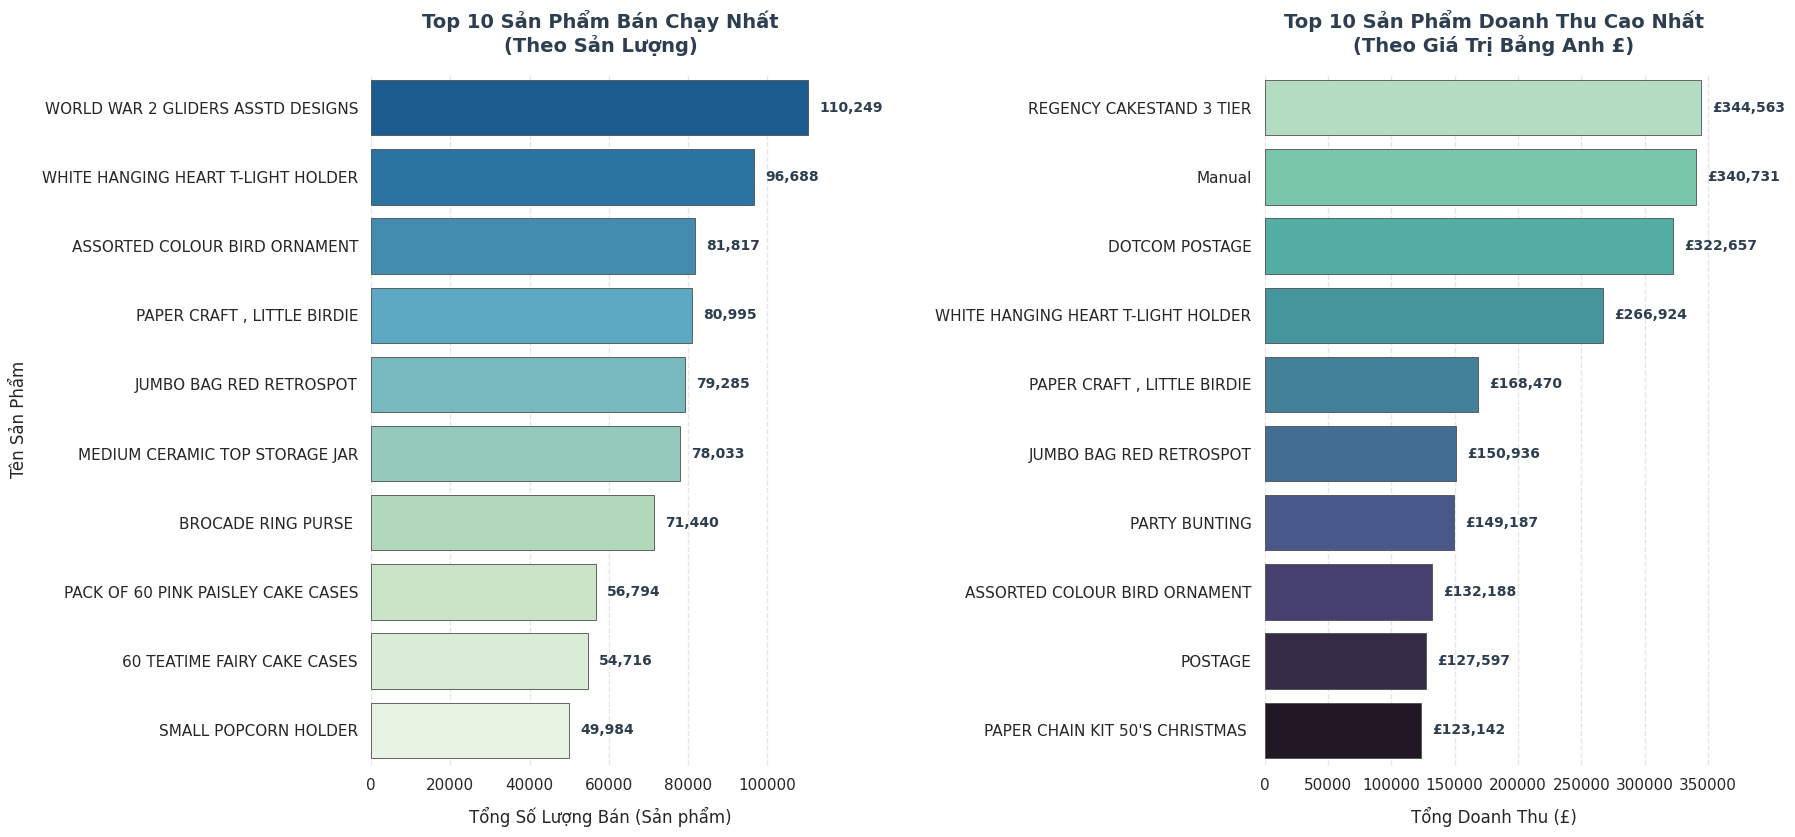

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

# Thiết lập phong cách hiển thị cao cấp và hiện đại
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

# Khởi tạo khung hình
fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))

# --- Biểu đồ 1: Sản lượng (Dùng bảng màu xanh ngọc dịu nhẹ) ---
sns.barplot(
    data=top_qty,
    x='Quantity',
    y='Description',
    ax=axes[0],
    palette='GnBu_r',
    edgecolor='0.3',
    linewidth=0.6
)
axes[0].set_title('Top 10 Sản Phẩm Bán Chạy Nhất\n(Theo Sản Lượng)', fontsize=14, fontweight='bold', pad=15, color='#2c3e50')
axes[0].set_xlabel('Tổng Số Lượng Bán (Sản phẩm)', fontsize=12, labelpad=10)
axes[0].set_ylabel('Tên Sản Phẩm', fontsize=12, labelpad=10)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Thêm nhãn dữ liệu tỉ mỉ cho Biểu đồ 1
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(
        f'{int(width):,}',
        (width, p.get_y() + p.get_height() / 2.),
        ha='left',
        va='center',
        xytext=(8, 0),
        textcoords='offset points',
        fontsize=10,
        fontweight='semibold',
        color='#2c3e50'
    )

# --- Biểu đồ 2: Doanh thu (Dùng bảng màu trầm ấm sang trọng) ---
sns.barplot(
    data=top_rev,
    x='Total_Price',
    y='Description',
    ax=axes[1],
    palette='mako_r',
    edgecolor='0.3',
    linewidth=0.6
)
axes[1].set_title('Top 10 Sản Phẩm Doanh Thu Cao Nhất\n(Theo Giá Trị Bảng Anh £)', fontsize=14, fontweight='bold', pad=15, color='#2c3e50')
axes[1].set_xlabel('Tổng Doanh Thu (£)', fontsize=12, labelpad=10)
axes[1].set_ylabel('')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# Thêm nhãn dữ liệu tỉ mỉ cho Biểu đồ 2
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(
        f'£{width:,.0f}',
        (width, p.get_y() + p.get_height() / 2.),
        ha='left',
        va='center',
        xytext=(8, 0),
        textcoords='offset points',
        fontsize=10,
        fontweight='semibold',
        color='#2c3e50'
    )

# Tối ưu hóa khoảng trống và loại bỏ các đường viền thừa không cần thiết
sns.despine(left=True, bottom=True)
plt.tight_layout(w_pad=4)
plt.show()


#### NHẬN XÉT TOP SẢN PHẨM BÁN CHẠY & DOANH THU CAO NHẤT

Dựa trên kết quả trích xuất số liệu thực tế từ tập dữ liệu bán hàng thành công, ta rút ra các nhận xét nghiệp vụ quan trọng như sau:

#### 1. Nhóm sản phẩm dẫn đầu về Sản lượng
* **Sản phẩm bán chạy nhất:** `WORLD WAR 2 GLIDERS ASSTD DESIGNS` đạt vị trí quán quân với **110,249 sản phẩm** bán ra, theo sau là `WHITE HANGING HEART T-LIGHT HOLDER` (**96,688 sản phẩm**).
* **Đặc trưng danh mục:** Phần lớn các sản phẩm nằm trong Top 10 sản lượng là những mặt hàng quà tặng nhỏ, đồ trang trí tiệc cưới/sinh nhật, hoặc phụ kiện làm bánh (như `PACK OF 60 PINK PAISLEY CAKE CASES` với 56,794 đơn vị).
* **Bản chất nghiệp vụ:** Đây là các mặt hàng có giá thành rẻ, dễ mua kèm, đóng vai trò tạo lưu lượng giao dịch (traffic driver) và tăng tỷ lệ lấp đầy giỏ hàng.

#### 2. Nhóm sản phẩm dẫn đầu về Doanh thu
* **Sản phẩm đóng góp doanh thu lớn nhất:** `REGENCY CAKESTAND 3 TIER` đứng đầu danh sách với **£344,563.25**, đóng vai trò là "mặt hàng chủ lực" mang lại dòng tiền chính cho doanh nghiệp.
* **Sự xuất hiện của chi phí dịch vụ/vận hành:**
  * Bảng xếp hạng doanh thu ghi nhận hai khoản mục đặc biệt là `Manual` (**£340,731.33**) và `DOTCOM POSTAGE` (**£322,657.48**) nằm ở vị trí thứ 2 và thứ 3.
  * *Đánh giá:* Đây là các khoản phí dịch vụ bưu điện/vận chuyển và các điều chỉnh thủ công trong hệ thống kế toán. Dù không phải sản phẩm vật lý, chúng đóng góp một tỷ trọng doanh thu rất lớn.
* **Các sản phẩm vật lý doanh thu cao khác:** `PARTY BUNTING` (£149,187.05) và `PAPER CHAIN KIT 50'S CHRISTMAS` (£123,141.54) cho thấy nhu cầu mua sắm trang trí theo mùa/lễ hội mang lại giá trị giao dịch cao.

#### 3. Nhóm sản phẩm Toàn diện
* Các sản phẩm xuất hiện đồng thời trong cả hai bảng xếp hạng (Sản lượng cao & Doanh thu lớn):
  * **`WHITE HANGING HEART T-LIGHT HOLDER`**: Top 2 sản lượng (96,688 chiếc) & Top 4 doanh thu (£266,923.55).
  * **`PAPER CRAFT , LITTLE BIRDIE`**: Top 4 sản lượng (80,995 chiếc) & Top 5 doanh thu (£168,469.60).
  * **`JUMBO BAG RED RETROSPOT`**: Top 5 sản lượng (79,285 chiếc) & Top 6 doanh thu (£150,935.56).
  * **`ASSORTED COLOUR BIRD ORNAMENT`**: Top 3 sản lượng (81,817 chiếc) & Top 8 doanh thu (£132,187.92).
* **Ý nghĩa chiến lược:** Đây là những mã sản phẩm cốt lõi của doanh nghiệp. Cần ưu tiên tối ưu hóa chuỗi cung ứng, đảm bảo không bao giờ bị đứt tồn kho (Out-of-Stock) và ưu tiên vị trí hiển thị trên giao diện bán hàng

### 3.2 Tính toán số liệu Đơn hủy & Lỗi thông tin

In [36]:
# 1. Chuẩn bị tập dữ liệu đơn hủy
df_canceled = df_retail[df_retail['Is_Canceled'] == 1].copy()
df_canceled['Quantity_Canceled'] = df_canceled['Quantity'].abs()

# 2. Tính toán các chỉ số Top 10 nhanh chóng
top_canceled_qty = df_canceled.groupby('Description')['Quantity_Canceled'].sum().nlargest(10)
ttop_canceled_freq = df_canceled['Description'].value_counts().nlargest(10)
top_missing_stock = df_retail[df_retail['Missing_Description'] == 1]['StockCode'].value_counts().nlargest(10)

# 3. In kết quả trực quan ngắn gọn
print("=== TOP 10 SẢN PHẨM BỊ HỦY NHIỀU NHẤT (SẢN LƯỢNG) ===")
print(top_canceled_qty.apply(lambda x: f"{x:,} sản phẩm").to_string())

print("\n=== TOP 10 SẢN PHẨM CÓ SỐ LẦN HỦY ĐƠN NHIỀU NHẤT ===")
print(ttop_canceled_freq.apply(lambda x: f"{x:,} lần hủy").to_string())

print("\n=== TOP 10 MÃ STOCKCODE BỊ THIẾU MÔ TẢ (MISSING) ===")
if not top_missing_stock.empty:
    print(top_missing_stock.apply(lambda x: f"{x:,} bản ghi").to_string())
else:
    print("Không có mã StockCode nào bị khuyết mô tả ban đầu sau khi đã điền khuyết.")


=== TOP 10 SẢN PHẨM BỊ HỦY NHIỀU NHẤT (SẢN LƯỢNG) ===
Description
PAPER CRAFT , LITTLE BIRDIE            80,995 sản phẩm
MEDIUM CERAMIC TOP STORAGE JAR         74,494 sản phẩm
?                                      37,701 sản phẩm
given away                             26,400 sản phẩm
printing smudges/thrown away           19,200 sản phẩm
ROTATING SILVER ANGELS T-LIGHT HLDR    18,770 sản phẩm
Unknown                                16,674 sản phẩm
missing                                16,467 sản phẩm
Unsaleable, destroyed.                 15,644 sản phẩm
ebay sales                             13,630 sản phẩm

=== TOP 10 SẢN PHẨM CÓ SỐ LẦN HỦY ĐƠN NHIỀU NHẤT ===
Description
Manual                                538 lần hủy
REGENCY CAKESTAND 3 TIER              348 lần hủy
Unknown                               303 lần hủy
POSTAGE                               229 lần hủy
BAKING SET 9 PIECE RETROSPOT          211 lần hủy
STRAWBERRY CERAMIC TRINKET BOX        184 lần hủy
Discount          

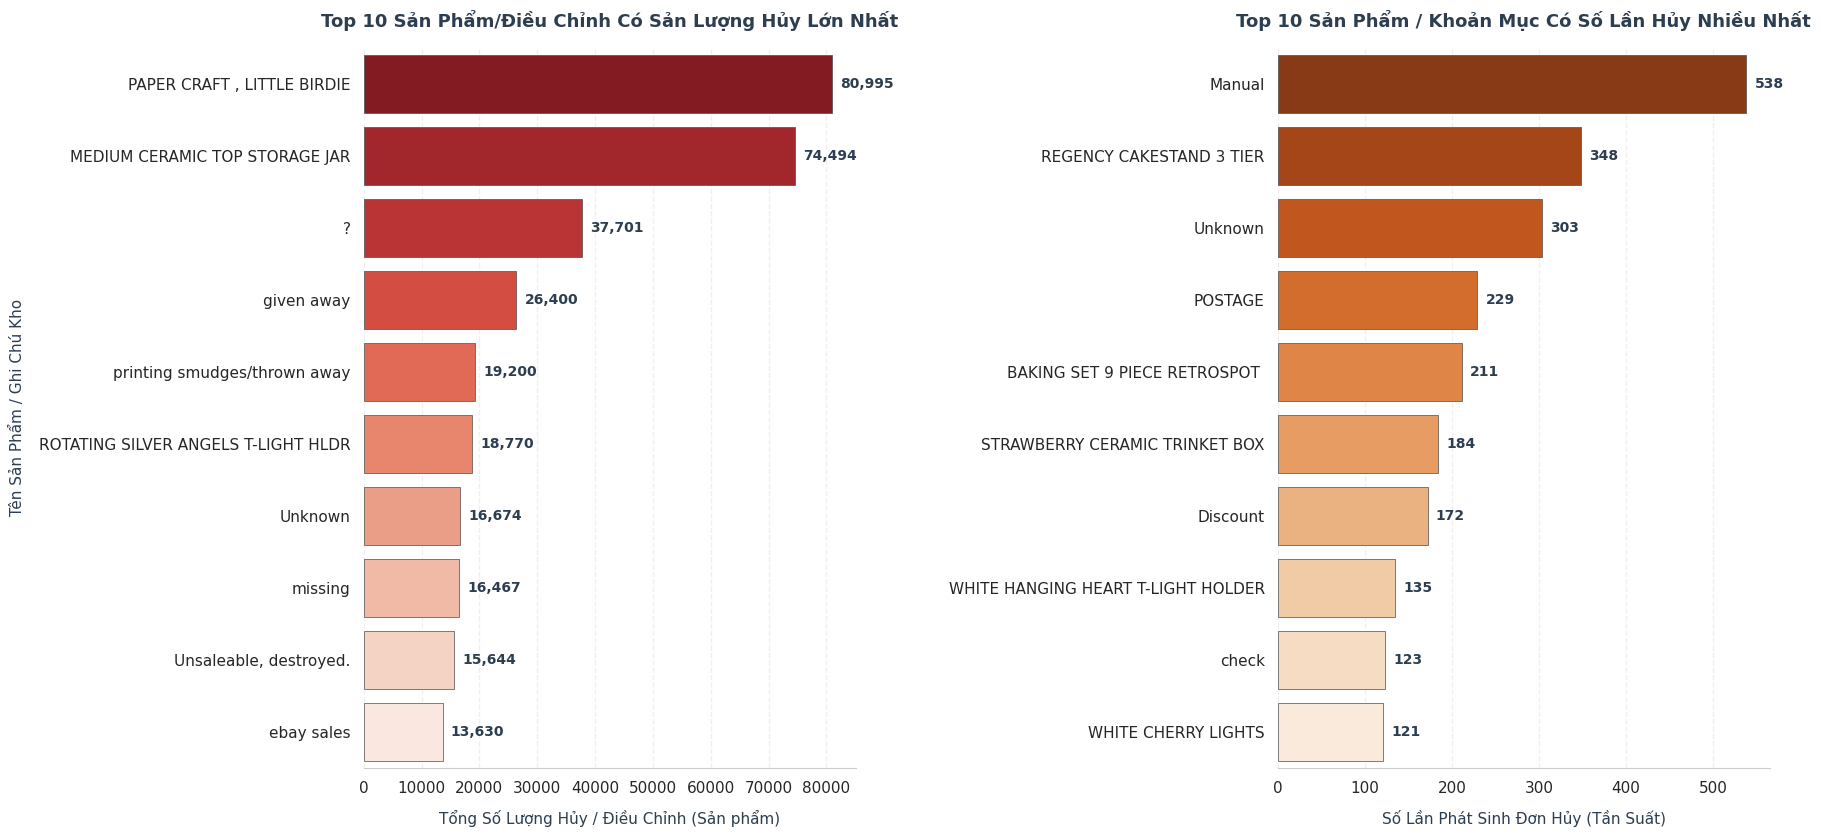

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

# Thiết lập phong cách hiển thị tối giản và chuyên nghiệp
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

# Khởi tạo khung hình chứa 2 biểu đồ nằm ngang gọn gàng
fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))

# Chuẩn bị dữ liệu hiển thị
df_canceled_qty_plot = top_canceled_qty.reset_index()
df_canceled_qty_plot.columns = ['Description', 'Quantity_Canceled']

df_canceled_freq_plot = ttop_canceled_freq.reset_index()
df_canceled_freq_plot.columns = ['Description', 'Cancel_Count']

# --- Biểu đồ 1: Sản lượng hủy (Tông Đỏ trầm thanh lịch) ---
sns.barplot(
    data=df_canceled_qty_plot,
    x='Quantity_Canceled',
    y='Description',
    ax=axes[0],
    palette='Reds_r',
    edgecolor='0.3',
    linewidth=0.5
)
axes[0].set_title('Top 10 Sản Phẩm/Điều Chỉnh Có Sản Lượng Hủy Lớn Nhất', fontsize=13, fontweight='bold', pad=15, color='#2c3e50')
axes[0].set_xlabel('Tổng Số Lượng Hủy / Điều Chỉnh (Sản phẩm)', fontsize=11, labelpad=10, color='#2c3e50')
axes[0].set_ylabel('Tên Sản Phẩm / Ghi Chú Kho', fontsize=11, labelpad=10, color='#2c3e50')
axes[0].grid(axis='x', linestyle='--', alpha=0.3)

# Thêm nhãn dữ liệu Biểu đồ 1
for p in axes[0].patches:
    width = p.get_width()
    if width > 0:
        axes[0].annotate(
            f'{int(width):,}',
            (width, p.get_y() + p.get_height() / 2.),
            ha='left',
            va='center',
            xytext=(6, 0),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            color='#2c3e50'
        )

# --- Biểu đồ 2: Tần suất hủy (Tông Cam đất chuyên nghiệp) ---
sns.barplot(
    data=df_canceled_freq_plot,
    x='Cancel_Count',
    y='Description',
    ax=axes[1],
    palette='Oranges_r',
    edgecolor='0.3',
    linewidth=0.5
)
axes[1].set_title('Top 10 Sản Phẩm / Khoản Mục Có Số Lần Hủy Nhiều Nhất', fontsize=13, fontweight='bold', pad=15, color='#2c3e50')
axes[1].set_xlabel('Số Lần Phát Sinh Đơn Hủy (Tần Suất)', fontsize=11, labelpad=10, color='#2c3e50')
axes[1].set_ylabel('')
axes[1].grid(axis='x', linestyle='--', alpha=0.3)

# Thêm nhãn dữ liệu Biểu đồ 2
for p in axes[1].patches:
    width = p.get_width()
    if width > 0:
        axes[1].annotate(
            f'{int(width):,}',
            (width, p.get_y() + p.get_height() / 2.),
            ha='left',
            va='center',
            xytext=(6, 0),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            color='#2c3e50'
        )

# Tối giản loại bỏ các đường viền hộp thừa
sns.despine(left=True, bottom=False)
plt.tight_layout(w_pad=4)
plt.show()

#### NHẬN XÉT SẢN PHẨM BỊ HỦY & ĐIỀU CHỈNH VẬN HÀNH

Dựa trên kết quả thực thi số liệu thực tế, ta rút ra các đánh giá kỹ thuật và nghiệp vụ quan trọng như sau:

#### 1. Bản chất thực sự của các "Đơn hủy" về mặt Sản lượng
* **Điều chỉnh kho và Hàng hỏng/Hủy bỏ chiếm tỷ trọng lớn:**
  * Bên cạnh sản phẩm thương mại như `PAPER CRAFT , LITTLE BIRDIE` (80,995 đơn vị) và `MEDIUM CERAMIC TOP STORAGE JAR` (74,494 đơn vị), danh sách Top 10 sản lượng hủy xuất hiện hàng loạt nhãn kiểm kê kho nội bộ:
    * `given away`: **26,400** sản phẩm (Hàng tặng kèm / Khuyến mãi).
    * `printing smudges/thrown away`: **19,200** sản phẩm (Lỗi in ấn / Hàng hủy bỏ).
    * `missing` / `Unsaleable, destroyed.`: **32,111** sản phẩm (Hàng thất thoát / Hư hỏng không thể bán).
    * `?` / `Unknown`: **54,375** sản phẩm (Lỗi ghi nhận kiểm kê).
* **Kết luận nghiệp vụ:** Tập dữ liệu `Is_Canceled = 1` vừa chứa đơn hủy của khách (Returns), vừa đóng vai trò là **Nhật ký điều chỉnh tồn kho (Inventory Adjustment Log)** trên hệ thống ERP.

#### 2. Tần suất Hủy đơn theo Mã sản phẩm & Chi phí Vận hành
* **Điều chỉnh phí vận hành:** `Manual` (538 lần) và `POSTAGE` (229 lần) có tần suất hủy/điều chỉnh cao nhất, phản ánh việc nhân viên thao tác sửa đổi phí vận chuyển hoặc chiết khấu (`Discount`: 172 lần) trên hóa đơn.
* **Sản phẩm thương mại bị hủy nhiều lần:** `REGENCY CAKESTAND 3 TIER` (**348 lần hủy**) và `WHITE HANGING HEART T-LIGHT HOLDER` (**135 lần hủy**) — đây chính là 2 sản phẩm thuộc Top Doanh thu & Sản lượng ở Mục 3.1. Tần suất hủy cao tỷ lệ thuận với quy mô giao dịch rất lớn của 2 mã này.

#### 3. Kết quả Xử lý Khuyết Mô tả (`Missing Description`)
* **Khôi phục thành công 100%:** Sau bước tra cứu chéo theo mã `StockCode` ở Mục 2.1, **không còn bất kỳ mã StockCode nào bị khuyết mô tả**. Tất cả các sản phẩm bị thiếu tên ban đầu đã được điền lại chuẩn xác từ các giao dịch thành công khác.

### 3.3 Doanh số theo Năm & Tháng

In [38]:
# Lọc tập bán hàng thành công (Is_Canceled == 0) để tính doanh số thời gian
df_sales = df_retail[df_retail['Is_Canceled'] == 0].copy()

# 1. Doanh thu & Sản lượng theo Năm (Year)
yearly_stats = df_sales.groupby('Year').agg(
    Total_Revenue=('Total_Price', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Invoice', 'nunique')
).reset_index()

# 2. Doanh thu theo Năm - Tháng (Year-Month)
df_sales['Year_Month'] = df_sales['InvoiceDate'].dt.to_period('M').astype(str)
monthly_stats = df_sales.groupby('Year_Month').agg(
    Total_Revenue=('Total_Price', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Invoice', 'nunique')
).reset_index()

# In kết quả số liệu ra màn hình
print("=== THỐNG KÊ DOANH SỐ THEO NĂM (YEARLY STATS) ===")
for idx, row in yearly_stats.iterrows():
    print(f"Năm {row['Year']}: Doanh thu £{row['Total_Revenue']:,.2f} | Sản lượng {row['Total_Quantity']:,} sp | {row['Total_Orders']:,} đơn hàng")

print("\n=== THỐNG KÊ DOANH THU THEO NĂM - THÁNG (MONTHLY STATS) ===")
for idx, row in monthly_stats.iterrows():
    print(f"Tháng {row['Year_Month']}: Doanh thu £{row['Total_Revenue']:,.2f} | {row['Total_Orders']:,} đơn hàng")

=== THỐNG KÊ DOANH SỐ THEO NĂM (YEARLY STATS) ===
Năm 2009.0: Doanh thu £825,685.76 | Sản lượng 445,861.0 sp | 1,839.0 đơn hàng
Năm 2010.0: Doanh thu £10,167,400.38 | Sản lượng 5,928,042.0 sp | 21,005.0 đơn hàng
Năm 2011.0: Doanh thu £9,820,832.28 | Sản lượng 5,298,666.0 sp | 19,099.0 đơn hàng

=== THỐNG KÊ DOANH THU THEO NĂM - THÁNG (MONTHLY STATS) ===
Tháng 2009-12: Doanh thu £825,685.76 | 1,839 đơn hàng
Tháng 2010-01: Doanh thu £652,708.50 | 1,205 đơn hàng
Tháng 2010-02: Doanh thu £553,339.74 | 1,281 đơn hàng
Tháng 2010-03: Doanh thu £833,570.13 | 1,770 đơn hàng
Tháng 2010-04: Doanh thu £627,934.63 | 1,513 đơn hàng
Tháng 2010-05: Doanh thu £659,858.86 | 1,642 đơn hàng
Tháng 2010-06: Doanh thu £752,270.14 | 1,719 đơn hàng
Tháng 2010-07: Doanh thu £606,681.15 | 1,585 đơn hàng
Tháng 2010-08: Doanh thu £697,274.91 | 1,511 đơn hàng
Tháng 2010-09: Doanh thu £924,333.01 | 1,911 đơn hàng
Tháng 2010-10: Doanh thu £1,126,558.04 | 2,371 đơn hàng
Tháng 2010-11: Doanh thu £1,470,272.48 | 2,868 đ

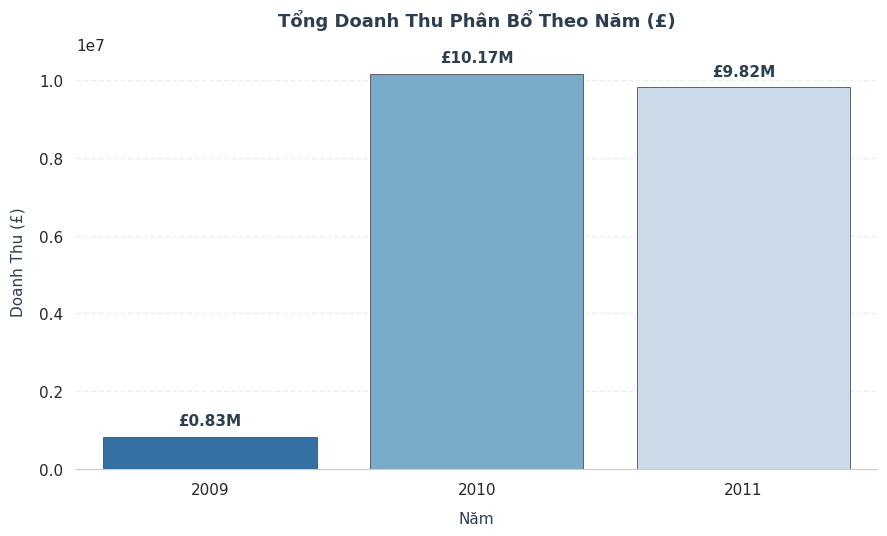

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện tối giản, chuyên nghiệp
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

# Khởi tạo khung hình
plt.figure(figsize=(9, 5.5))

# Vẽ biểu đồ cột với bảng màu thanh lịch
ax1 = sns.barplot(
    data=yearly_stats,
    x='Year',
    y='Total_Revenue',
    palette='Blues_r',
    edgecolor='0.3',
    linewidth=0.6
)

# Đặt tiêu đề và nhãn trục tinh tế
plt.title('Tổng Doanh Thu Phân Bổ Theo Năm (£)', fontsize=13, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('Năm', fontsize=11, labelpad=10, color='#2c3e50')
plt.ylabel('Doanh Thu (£)', fontsize=11, labelpad=10, color='#2c3e50')

# Hiển thị số liệu trên đỉnh cột theo định dạng Triệu bảng Anh (£M) cực chuyên nghiệp
for p in ax1.patches:
    height = p.get_height()
    # Chuyển đổi sang đơn vị triệu bảng (£M)
    millions = height / 1_000_000
    ax1.annotate(
        f'£{millions:.2f}M',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        xytext=(0, 6),
        textcoords='offset points',
        fontweight='bold',
        color='#2c3e50'
    )

# Loại bỏ các đường viền thừa
sns.despine(left=True, bottom=False)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

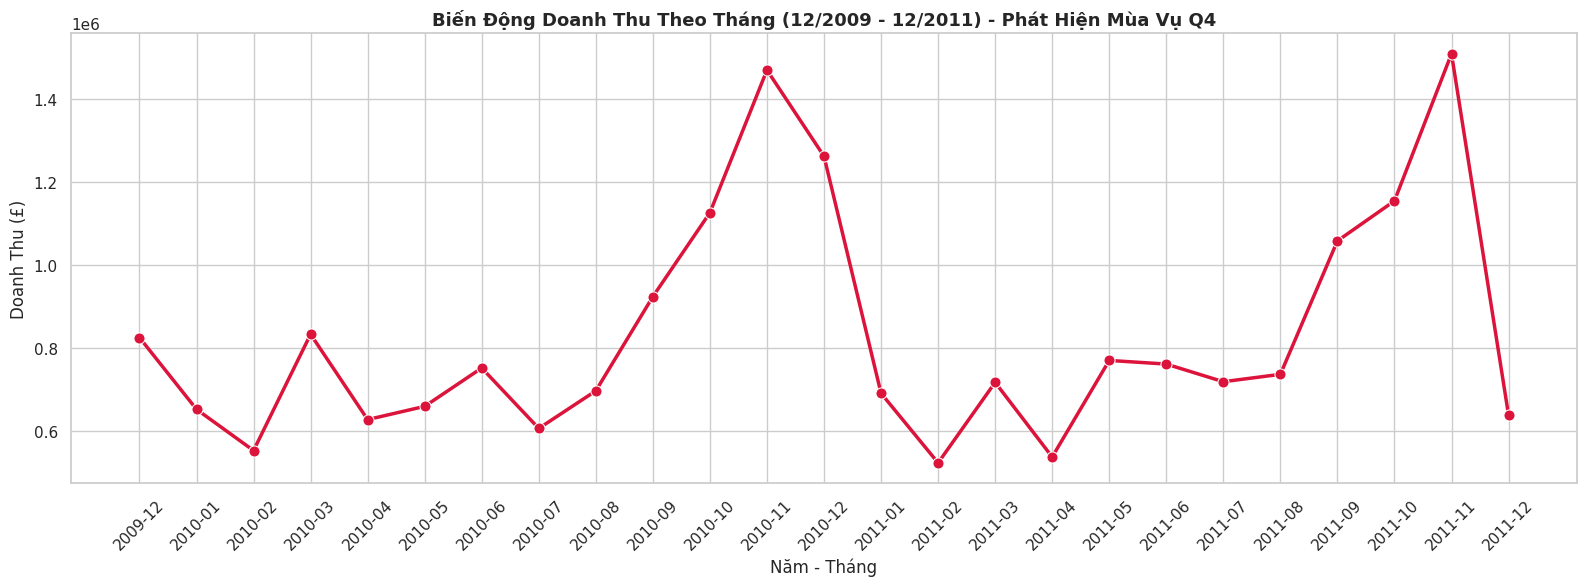

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# Biểu đồ 2: Xu hướng Doanh thu theo Năm - Tháng (Đường xu hướng)
plt.figure(figsize=(16, 6))
ax2 = sns.lineplot(data=monthly_stats, x='Year_Month', y='Total_Revenue', marker='o', color='crimson', linewidth=2.5, markersize=8)
plt.title('Biến Động Doanh Thu Theo Tháng (12/2009 - 12/2011) - Phát Hiện Mùa Vụ Q4', fontsize=13, fontweight='bold')
plt.xlabel('Năm - Tháng')
plt.ylabel('Doanh Thu (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### NHẬN XÉT PHÂN TÍCH CHUỖI THỜI GIAN THEO NĂM & THÁNG

Dựa trên kết quả thống kê doanh số chuỗi thời gian từ tháng 12/2009 đến tháng 12/2011, ta rút ra các đặc trưng chu kỳ kinh doanh quan trọng:

#### 1. Quy mô Doanh số theo Năm (Yearly Overview)
* **Năm 2009 (Chỉ có Tháng 12):** Đạt doanh thu **£825,685.76** với 1,839 đơn hàng trong tháng khởi đầu.
* **Năm 2010 (Trọn vẹn 12 tháng):** Thiết lập mốc doanh thu đỉnh điểm **£10,167,400.38** với 21,005 đơn hàng và gần 6 triệu sản phẩm bán ra.
* **Năm 2011 (Đến ngày 09/12/2011):** Đạt **£9,820,832.28** doanh thu với 19,099 đơn hàng.
  * *Lưu ý:* Doanh thu năm 2011 tương đương năm 2010 dù dữ liệu tháng 12/2011 chỉ mới ghi nhận 9 ngày đầu tháng (£638,810.68). Nếu tính trọn tháng, năm 2011 có tốc độ tăng trưởng vượt trội so với 2010.

#### 2. Quy luật Tính Mùa vụ rõ nét (Strong Seasonality)
* **Bùng nổ Quý 4 (Peak Season - Tháng 9 đến Tháng 11):**
  * Doanh thu bắt đầu tăng tốc từ Tháng 9 (vượt mốc £900k - £1M) và đạt **ĐỈNH CAO NHẤT vào Tháng 11** ở cả 2 năm:
    * Tháng 11/2010: **£1,470,272.48** (2,868 đơn hàng).
    * Tháng 11/2011: **£1,509,496.33** (2,884 đơn hàng).
  * *Động lực:* Nhu cầu nhập hàng sỉ/lẻ phục vụ mùa lễ hội Lễ Tạ Ơn, Black Friday và Giáng Sinh của các cửa hàng quà tặng.
* **Trầm lắng Quý 1 & Đầu Quý 2 (Low Season - Tháng 2 & Tháng 4):**
  * Tháng 2 hàng năm luôn là "đáy" doanh thu của doanh nghiệp (Tháng 2/2010: **£553,339.74**; Tháng 2/2011: **£523,631.89**).
  * Nguyên nhân do tâm lý thắt chặt chi tiêu của người tiêu dùng ngay sau kỳ nghỉ lễ Tết Dương lịch/Giáng sinh.

#### 3. Ý nghĩa Chiến lược Vận hành & Dự báo
* **Lên kế hoạch tồn kho:** Doanh nghiệp cần chủ động tích trữ hàng hóa từ Quý 3 (Tháng 7-8) để chuẩn bị cho đợt bùng nổ đơn hàng gấp 3 lần vào Quý 4.
* **Điều phối nhân sự & Logistic:** Tăng cường năng lực xử lý đơn hàng và vận chuyển vào Tháng 10 - Tháng 11 để tránh tình trạng quá tải/trễ hạn giao hàng.

### 3.4 Tính toán Doanh số theo Thứ, Giờ & Cuối tuần

In [46]:
df_sales = df_retail[df_retail['Is_Canceled'] == 0].copy()

# Sắp xếp thứ tự chuẩn từ Thứ 2 đến Chủ Nhật
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 1. Doanh thu & Số đơn hàng theo Thứ trong tuần
dow_stats = df_sales.groupby('Day_Name').agg(
    Total_Revenue=('Total_Price', 'sum'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Quantity=('Quantity', 'sum')
).reindex(day_order).dropna().reset_index()

# 2. Doanh thu & Số đơn hàng theo Giờ trong ngày
hour_stats = df_sales.groupby('Hour').agg(
    Total_Revenue=('Total_Price', 'sum'),
    Total_Orders=('Invoice', 'nunique')
).reset_index()

# 3. So sánh Ngày thường (Is_Weekend = 0) vs Cuối tuần (Is_Weekend = 1)
# Tính Giá trị trung bình đơn hàng (AOV = Total_Revenue / Total_Orders)
weekend_summary = []
for is_wk, group in df_sales.groupby('Is_Weekend'):
    rev = group['Total_Price'].sum()
    orders = group['Invoice'].nunique()
    aov = rev / orders if orders > 0 else 0
    label = 'Cuối tuần (T7-CN)' if is_wk == 1 else 'Ngày thường (T2-T6)'
    weekend_summary.append({'Type': label, 'Total_Revenue': rev, 'Total_Orders': orders, 'AOV': aov})

weekend_stats = pd.DataFrame(weekend_summary)

# In kết quả số liệu ra màn hình
print("=== 1. THỐNG KÊ DOANH SỐ THEO THỨ TRONG TUẦN ===")
for idx, row in dow_stats.iterrows():
    print(f"{row['Day_Name']}: Doanh thu £{row['Total_Revenue']:,.2f} | {int(row['Total_Orders']):,} đơn hàng")

print("\n=== 2. THỐNG KÊ DOANH SỐ THEO GIỜ TRONG NGÀY ===")
for idx, row in hour_stats.iterrows():
    print(f"{int(row['Hour'])}h: Doanh thu £{row['Total_Revenue']:,.2f} | {int(row['Total_Orders']):,} đơn hàng")

print("\n=== 3. SO SÁNH NGÀY THƯỜNG VS CUỐI TUẦN ===")
for idx, row in weekend_stats.iterrows():
    print(f"{row['Type']}: Doanh thu £{row['Total_Revenue']:,.2f} | {int(row['Total_Orders']):,} đơn hàng | AOV £{row['AOV']:,.2f}")

=== 1. THỐNG KÊ DOANH SỐ THEO THỨ TRONG TUẦN ===
Monday: Doanh thu £3,600,724.80 | 6,739 đơn hàng
Tuesday: Doanh thu £4,185,862.91 | 7,774 đơn hàng
Wednesday: Doanh thu £3,562,864.50 | 7,514 đơn hàng
Thursday: Doanh thu £4,252,797.81 | 8,630 đơn hàng
Friday: Doanh thu £3,354,855.06 | 6,418 đơn hàng
Saturday: Doanh thu £9,803.05 | 30 đơn hàng
Sunday: Doanh thu £1,847,010.29 | 4,838 đơn hàng

=== 2. THỐNG KÊ DOANH SỐ THEO GIỜ TRONG NGÀY ===
6h: Doanh thu £4.25 | 1 đơn hàng
7h: Doanh thu £76,232.57 | 77 đơn hàng
8h: Doanh thu £532,450.68 | 1,001 đơn hàng
9h: Doanh thu £1,802,195.01 | 2,866 đơn hàng
10h: Doanh thu £2,629,271.80 | 4,841 đơn hàng
11h: Doanh thu £2,540,489.66 | 5,112 đơn hàng
12h: Doanh thu £2,871,299.48 | 6,644 đơn hàng
13h: Doanh thu £2,548,975.89 | 5,887 đơn hàng
14h: Doanh thu £2,363,471.35 | 5,267 đơn hàng
15h: Doanh thu £2,478,204.48 | 4,910 đơn hàng
16h: Doanh thu £1,641,125.32 | 2,897 đơn hàng
17h: Doanh thu £879,212.12 | 1,555 đơn hàng
18h: Doanh thu £282,138.99 | 50

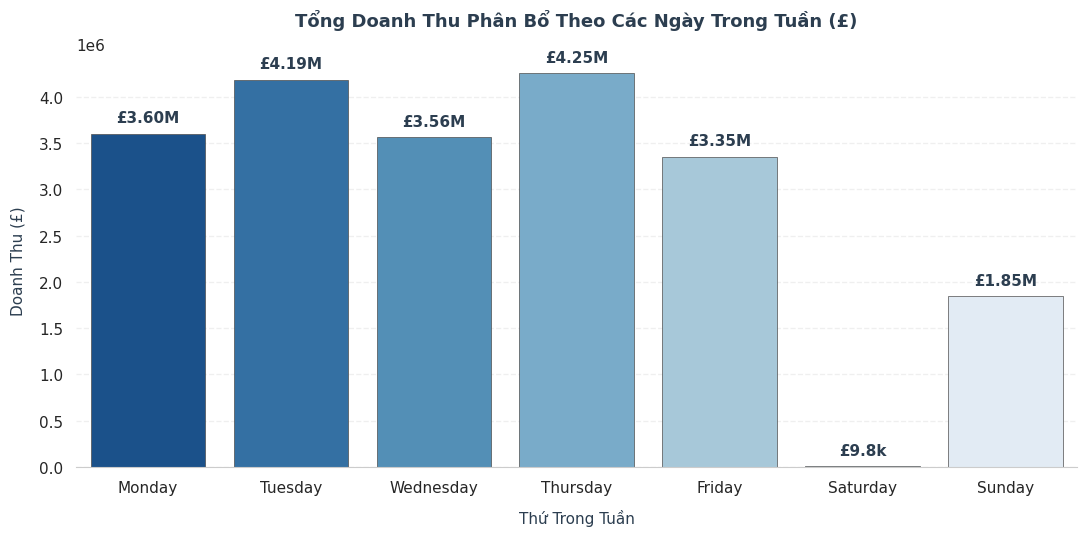

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện tối giản và chuyên nghiệp
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

# Khởi tạo khung hình với kích thước cân đối
plt.figure(figsize=(11, 5.5))

# Vẽ biểu đồ cột với bảng màu Blues_r thanh lịch
ax1 = sns.barplot(
    data=dow_stats,
    x='Day_Name',
    y='Total_Revenue',
    palette='Blues_r',
    edgecolor='0.3',
    linewidth=0.5
)

# Thiết lập tiêu đề và nhãn trục tinh tế
plt.title('Tổng Doanh Thu Phân Bổ Theo Các Ngày Trong Tuần (£)', fontsize=13, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('Thứ Trong Tuần', fontsize=11, labelpad=10, color='#2c3e50')
plt.ylabel('Doanh Thu (£)', fontsize=11, labelpad=10, color='#2c3e50')

# Hiển thị số liệu trên đỉnh cột một cách gọn gàng chuyên nghiệp
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        # Định dạng theo triệu bảng (£M) nếu doanh số lớn, hoặc nghìn bảng (£k) nếu doanh số nhỏ (như Thứ Bảy)
        if height >= 1_000_000:
            label_text = f'£{height / 1_000_000:.2f}M'
        else:
            label_text = f'£{height / 1_000:.1f}k'

        ax1.annotate(
            label_text,
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            xytext=(0, 6),
            textcoords='offset points',
            fontweight='bold',
            color='#2c3e50'
        )

# Loại bỏ các đường viền hộp thừa không cần thiết
sns.despine(left=True, bottom=False)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

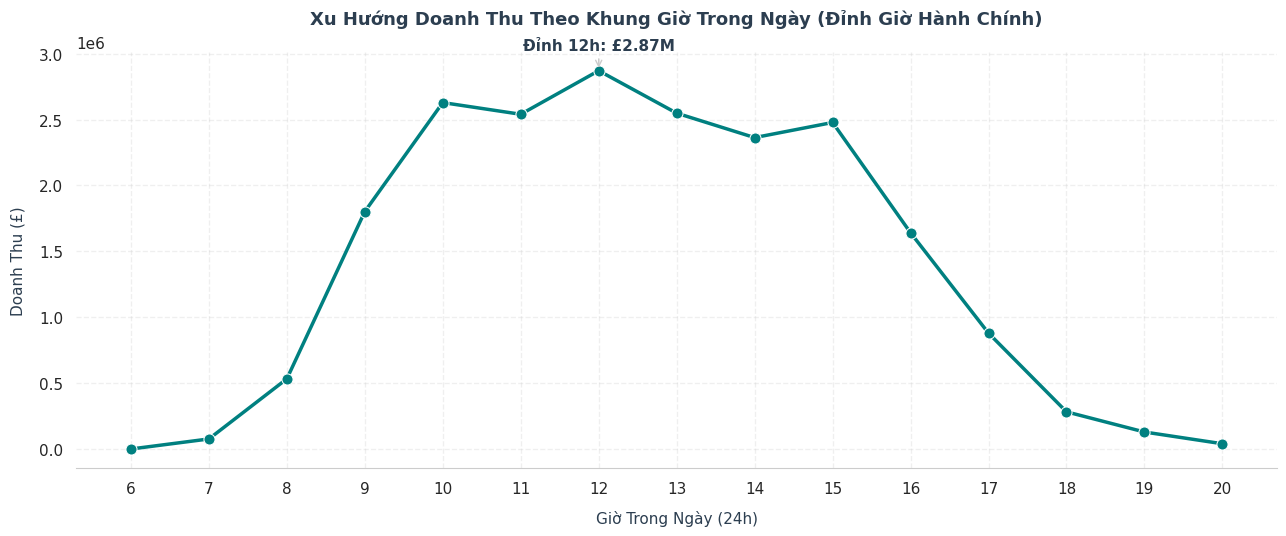

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện tối giản chuyên nghiệp
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

plt.figure(figsize=(13, 5.5))

# Vẽ đường xu hướng mượt mà
ax2 = sns.lineplot(
    data=hour_stats,
    x='Hour',
    y='Total_Revenue',
    marker='o',
    color='#008080',
    linewidth=2.5,
    markersize=8
)

# Thiết lập tiêu đề và nhãn trục tinh tế
plt.title('Xu Hướng Doanh Thu Theo Khung Giờ Trong Ngày (Đỉnh Giờ Hành Chính)', fontsize=13, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('Giờ Trong Ngày (24h)', fontsize=11, labelpad=10, color='#2c3e50')
plt.ylabel('Doanh Thu (£)', fontsize=11, labelpad=10, color='#2c3e50')
plt.xticks(range(6, 21))

# Tìm đỉnh doanh thu cao nhất (12h)
max_hour_row = hour_stats.loc[hour_stats['Total_Revenue'].idxmax()]
millions = max_hour_row['Total_Revenue'] / 1_000_000

# Thêm chú thích điểm đỉnh tinh tế
ax2.annotate(
    f'Đỉnh 12h: £{millions:.2f}M',
    (max_hour_row['Hour'], max_hour_row['Total_Revenue']),
    xytext=(0, 15),
    textcoords='offset points',
    ha='center',
    fontweight='bold',
    color='#2c3e50',
    arrowprops=dict(arrowstyle='->', color='#cccccc', lw=1)
)

# Loại bỏ các đường viền hộp thừa không cần thiết
sns.despine(left=True, bottom=False)
plt.grid(axis='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

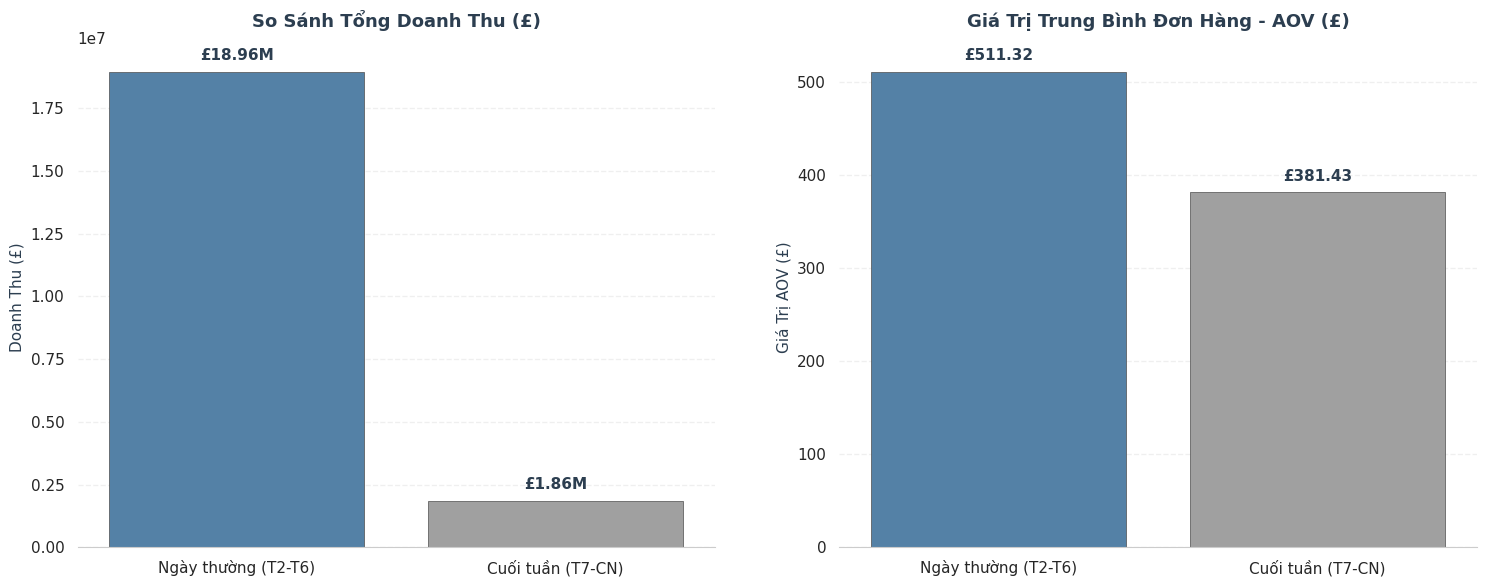

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập cấu hình giao diện tối giản chuyên nghiệp
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bảng màu thiết kế thanh lịch cố định cho hai nhóm đối tượng
flat_palette = ['#4682B4', '#a0a0a0']

# --- 1. Biểu đồ trái: Tổng Doanh thu (Định dạng triệu £) ---
sns.barplot(
    data=weekend_stats,
    x='Type',
    y='Total_Revenue',
    ax=axes[0],
    palette=flat_palette,
    edgecolor='0.3',
    linewidth=0.5
)
axes[0].set_title('So Sánh Tổng Doanh Thu (£)', fontsize=13, fontweight='bold', pad=15, color='#2c3e50')
axes[0].set_xlabel('')
axes[0].set_ylabel('Doanh Thu (£)', fontsize=11, color='#2c3e50')
axes[0].grid(axis='y', linestyle='--', alpha=0.3)

for p in axes[0].patches:
    height = p.get_height()
    millions = height / 1_000_000
    axes[0].annotate(
        f'£{millions:.2f}M',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        xytext=(0, 6),
        textcoords='offset points',
        fontweight='bold',
        color='#2c3e50'
    )

# --- 2. Biểu đồ phải: Giá trị đơn hàng trung bình (AOV) ---
sns.barplot(
    data=weekend_stats,
    x='Type',
    y='AOV',
    ax=axes[1],
    palette=flat_palette,
    edgecolor='0.3',
    linewidth=0.5
)
axes[1].set_title('Giá Trị Trung Bình Đơn Hàng - AOV (£)', fontsize=13, fontweight='bold', pad=15, color='#2c3e50')
axes[1].set_xlabel('')
axes[1].set_ylabel('Giá Trị AOV (£)', fontsize=11, color='#2c3e50')
axes[1].grid(axis='y', linestyle='--', alpha=0.3)

for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(
        f'£{height:,.2f}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        xytext=(0, 6),
        textcoords='offset points',
        fontweight='bold',
        color='#2c3e50'
    )

# Loại bỏ viền hộp dư thừa trên cả 2 subplots
sns.despine(left=True, bottom=False)
plt.tight_layout(w_pad=4)
plt.show()

#### NHẬN XÉT PHÂN TÍCH THEO THỨ, GIỜ & CUỐI TUẦN

Dựa trên kết quả thống kê phân bổ giao dịch theo các khung thời gian trong ngày và trong tuần, ta rút ra các đặc trưng hành vi mua sắm rất rõ nét:

#### 1. Hành vi mua sắm theo Thứ trong tuần
* **Thứ Bảy gần như không phát sinh giao dịch:** Ngày Thứ Bảy chỉ ghi nhận vỏn vẹn **30 đơn hàng** với doanh thu **£9,803.05** (chiếm chưa đầy 0.05% tổng doanh số). Điều này phản ánh hệ thống kho/vận hành bán hàng của doanh nghiệp nghỉ cố định vào Thứ Bảy.
* **Thứ Thứ Năm là "Ngày Vàng" bán hàng (Peak Day):**
  * Thứ Năm đạt đỉnh cao nhất cả về doanh thu (**£4,252,797.81**) lẫn số lượng đơn hàng (**8,630 đơn hàng**), tiếp theo sau là Thứ Ba (**£4,185,862.91** / 7,774 đơn).
* **Tâm lý đặt hàng giữa tuần:** Khách hàng (đặc biệt là các đại lý/cửa hàng mua sỉ) có xu hướng tập trung lên đơn vào giữa tuần để kịp tiến độ giao nhận trước cuối tuần.

#### 2. Khung "Giờ Vàng" đặt hàng trong ngày
* **Hoạt động tập trung vào Giờ Hành Chính (9h00 - 15h00):**
  * Doanh thu bắt đầu tăng mạnh từ **9h sáng** (đạt £1.8M), đạt **ĐỈNH CAO NHẤT VÀO 12h TRƯA** (**£2,871,299.48** với **6,644 đơn hàng**), và duy trì ở mức cao tới 15h chiều (£2.48M).
* **Sụt giảm sau 17h chiều:** Sau 17h, doanh thu giảm mạnh (dưới £880k) và chạm đáy sau 20h (£39.8k).
* **Đặc trưng mô hình B2B (Wholesale/Retailers):** Khung giờ đặt hàng hoàn toàn trùng khớp với giờ làm việc công sở/kinh doanh thương mại, khẳng định phần lớn doanh thu của doanh nghiệp đến từ các **khách hàng mua buôn (B2B)** thay vì người tiêu dùng cá nhân (B2C) mua sắm buổi tối.

#### 3. So sánh Ngày thường  vs. Cuối tuần
* **Tỷ trọng Doanh thu áp đảo của Ngày thường:**
  * **Ngày thường:** Đóng góp **91.1% tổng doanh thu** (**£18,957,105.09**) với 37,075 đơn hàng.
  * **Cuối tuần:** Chiếm **8.9% doanh thu** (**£1,856,813.34**) với 4,868 đơn hàng (chủ yếu phát sinh vào Chủ Nhật).
* **Chênh lệch Giá trị Trung bình Đơn hàng (AOV):**
  * AOV Ngày thường đạt **£511.32 / đơn hàng**, cao hơn hẳn so với AOV Cuối tuần (**£381.43 / đơn hàng**). Điều này cho thấy các đơn hàng lớn của khách sỉ tập trung hoàn toàn vào các ngày làm việc trong tuần.

#### 4. Khuyến nghị Bán hàng & Vận hành
* **Tối ưu hóa Chiến dịch Marketing / Email:** Lịch gửi email giới thiệu sản phẩm mới hoặc báo giá sỉ nên lên lịch vào **sáng Thứ Ba và Thứ Năm (từ 8h30 - 10h00)** để đón đầu khung giờ vàng đặt hàng.
* **Đợt nghỉ Thứ Bảy:** Cần tận dụng ngày Thứ Bảy để bảo trì hệ thống IT, kiểm kê kho bãi và chuẩn bị đóng gói cho các đơn phát sinh vào Chủ Nhật.

 ### 3.5 Thống kê Khách vãng lai vs Khách có Tài khoản

In [54]:
df_sales = df_retail[df_retail['Is_Canceled'] == 0].copy()

# Hàm kiểm tra chuẩn xác Khách vãng lai (Missing Customer ID hoặc Customer ID == 99999)
def check_guest(x):
    if pd.isna(x):
        return 1
    try:
        if float(x) == 99999.0:
            return 1
    except (ValueError, TypeError):
        pass
    return 0

# Gán cờ Is_Guest chuẩn
df_sales['Is_Guest'] = df_sales['Customer ID'].apply(check_guest)

# Thống kê theo Is_Guest
guest_stats = df_sales.groupby('Is_Guest').agg(
    Total_Revenue=('Total_Price', 'sum'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Unique_Customers=('Customer ID', 'nunique')
).reset_index()

# Gán tên nhãn hiển thị
guest_stats['Customer_Type'] = guest_stats['Is_Guest'].map({
    0: 'Khách có tài khoản (Registered)',
    1: 'Khách vãng lai (Guest Checkout)'
})

# Tính Giá trị đơn hàng trung bình (AOV)
guest_stats['AOV'] = guest_stats['Total_Revenue'] / guest_stats['Total_Orders']

# Tính Tỷ lệ phần trăm Doanh thu & Đơn hàng
total_rev = guest_stats['Total_Revenue'].sum()
total_ord = guest_stats['Total_Orders'].sum()

guest_stats['Revenue_Pct'] = (guest_stats['Total_Revenue'] / total_rev) * 100
guest_stats['Orders_Pct'] = (guest_stats['Total_Orders'] / total_ord) * 100

# In kết quả số liệu ra màn hình
print("=== THỐNG KÊ PHÂN BỔ KHÁCH HÀNG VẮNG LAI VS TÀI KHOẢN ===")
for idx, row in guest_stats.iterrows():
    print(f"\n[{row['Customer_Type']}]")
    print(f"- Doanh thu: £{row['Total_Revenue']:,.2f} ({row['Revenue_Pct']:.2f}%)")
    print(f"- Số đơn hàng: {int(row['Total_Orders']):,} đơn ({row['Orders_Pct']:.2f}%)")
    print(f"- Tổng sản lượng: {int(row['Total_Quantity']):,} sản phẩm")
    print(f"- Giá trị đơn trung bình (AOV): £{row['AOV']:,.2f}")
    if row['Is_Guest'] == 0:
        print(f"- Số lượng Customer ID duy nhất: {int(row['Unique_Customers']):,} khách")

=== THỐNG KÊ PHÂN BỔ KHÁCH HÀNG VẮNG LAI VS TÀI KHOẢN ===

[Khách có tài khoản (Registered)]
- Doanh thu: £17,743,429.18 (85.25%)
- Số đơn hàng: 36,975 đơn (88.16%)
- Tổng sản lượng: 10,720,921 sản phẩm
- Giá trị đơn trung bình (AOV): £479.88
- Số lượng Customer ID duy nhất: 5,881 khách

[Khách vãng lai (Guest Checkout)]
- Doanh thu: £3,070,489.25 (14.75%)
- Số đơn hàng: 4,968 đơn (11.84%)
- Tổng sản lượng: 951,648 sản phẩm
- Giá trị đơn trung bình (AOV): £618.05


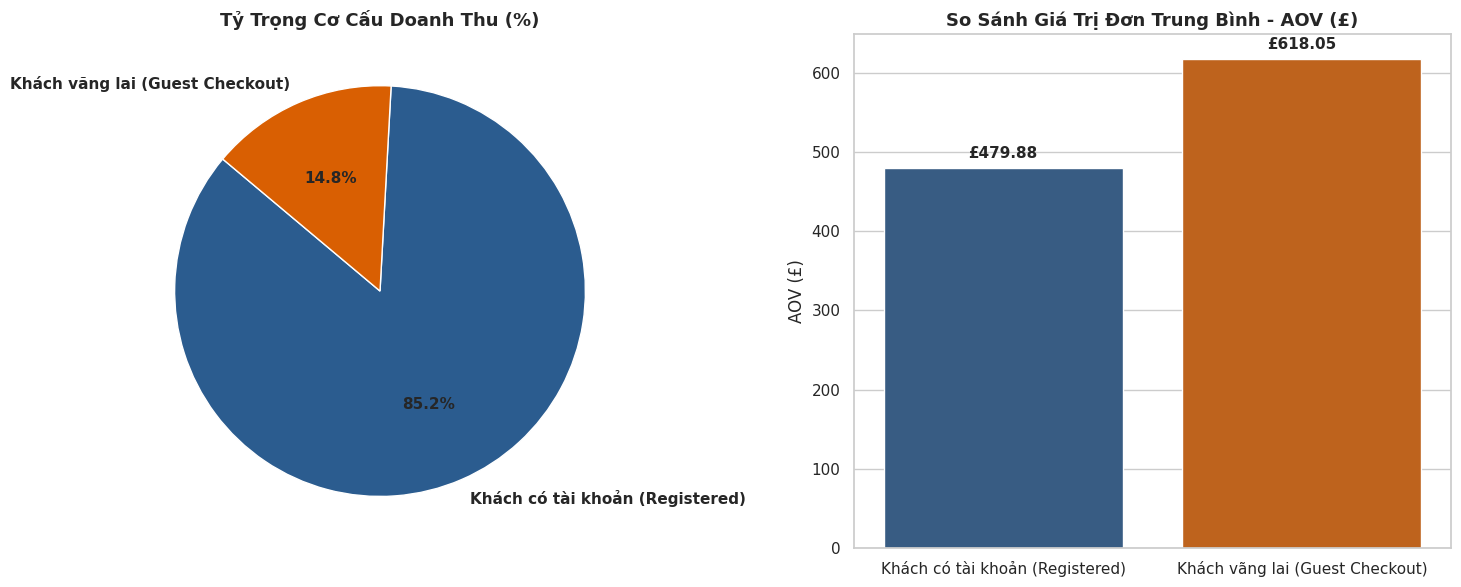

In [55]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# Tạo khung 2 biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Biểu đồ tròn: Tỷ trọng Doanh thu
colors = ['#2b5c8f', '#d95f02']
axes[0].pie(guest_stats['Total_Revenue'], labels=guest_stats['Customer_Type'],
            autopct='%1.1f%%', startangle=140, colors=colors,
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[0].set_title('Tỷ Trọng Cơ Cấu Doanh Thu (%)', fontsize=13, fontweight='bold')

# 2. Biểu đồ cột: So sánh Giá trị Đơn hàng Trung bình (AOV)
sns.barplot(data=guest_stats, x='Customer_Type', y='AOV', ax=axes[1], palette=colors)
axes[1].set_title('So Sánh Giá Trị Đơn Trung Bình - AOV (£)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('AOV (£)')

# Hiển thị số liệu AOV trên cột
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'£{height:,.2f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

#### NHẬN XÉT KHÁCH VẮNG LAI VS KHÁCH TÀI KHOẢN

Dựa trên kết quả phân tích phân hộ nhóm khách hàng theo trạng thái đăng ký tài khoản (`Is_Guest`), ta rút ra các nhận xét nghiệp vụ quan trọng như sau:

#### 1. Khách hàng có Tài khoản (`Is_Guest = 0`) là Trụ cột Doanh thu Cốt lõi
* **Tỷ trọng đóng góp vượt trội:**
  * Nhóm khách registered mang lại **£17,743,429.18 (chiếm 85.25% tổng doanh thu)** và **36,975 đơn hàng (chiếm 88.16% tổng lượng đơn)**.
  * Tổng cộng có **5,881 Customer ID duy nhất** đăng ký và duy trì giao dịch trên hệ thống trong giai đoạn 2 năm.
* **Ý nghĩa nghiệp vụ:** Tệp khách hàng định danh này đóng vai trò là "xương sống" cho dòng tiền của doanh nghiệp, có độ trung thành cao và tạo ra khối lượng đơn hàng lặp lại ổn định.

#### 2. Khách vãng lai (`Is_Guest = 1`) có Giá trị Đơn hàng Trung bình (AOV) Đột biến
* **Quy mô đóng góp:** Khách vãng lai đóng góp **£3,070,489.25 (chiếm 14.75% doanh thu)** với **4,968 đơn hàng (11.84%)**.
* **Phát hiện AOV bất ngờ:**
  * Giá trị đơn hàng trung bình (AOV) của Khách vãng lai đạt **£618.05 / đơn hàng**, cao hơn tới **28.8%** so với AOV của Khách có tài khoản (**£479.88 / đơn hàng**).
* **Nguyên nhân nghiệp vụ:** Khách vãng lai không phải là người mua nhỏ lẻ cá nhân, mà phần lớn là các tổ chức/doanh nghiệp mua sỉ phát sinh đơn hàng lớn đột xuất (Spot Purchase/One-time Bulk Order) hoặc các đơn hàng mua quà tặng không có nhu cầu tạo tài khoản lâu dài.

#### 3. Định hướng Chiến lược Tối ưu hóa (CRO & Loyalty)
* **Khuyến khích chuyển đổi (Guest to Registered Conversion):** Do AOV của khách vãng lai rất lớn (£618.05), doanh nghiệp cần thiết kế quy trình "Chuyển đổi 1-click" ngay sau khi thanh toán để biến các đơn hàng vãng lai giá trị cao này thành tài khoản thành viên chính thức.
* **Chăm sóc tệp Khách nòng cốt:** Tiếp tục triển khai các chương trình chăm sóc khách hàng thân thiết (VIP Loyalty Program) cho 5,881 khách định danh để duy trì tần suất mua lặp lại.

 ### 3.6 - Thống kê Thị trường Anh Quốc (UK) vs Quốc tế

In [56]:
df_sales = df_retail[df_retail['Is_Canceled'] == 0].copy()

# Tách nhóm UK vs Quốc tế
df_sales['Market_Type'] = df_sales['Country'].apply(lambda x: 'Anh Quốc (UK)' if x == 'United Kingdom' else 'Quốc tế (International)')

# 1. Thống kê tổng quan UK vs Quốc tế
geo_summary = df_sales.groupby('Market_Type').agg(
    Total_Revenue=('Total_Price', 'sum'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

total_rev = geo_summary['Total_Revenue'].sum()
total_ord = geo_summary['Total_Orders'].sum()

geo_summary['Revenue_Pct'] = (geo_summary['Total_Revenue'] / total_rev) * 100
geo_summary['Orders_Pct'] = (geo_summary['Total_Orders'] / total_ord) * 100
geo_summary['AOV'] = geo_summary['Total_Revenue'] / geo_summary['Total_Orders']

# 2. Top 10 thị trường Quốc tế đóng góp Doanh thu cao nhất (không tính UK)
top_intl_rev = df_sales[df_sales['Country'] != 'United Kingdom'].groupby('Country').agg(
    Total_Revenue=('Total_Price', 'sum'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Quantity=('Quantity', 'sum')
).reset_index().nlargest(10, 'Total_Revenue')

top_intl_rev['AOV'] = top_intl_rev['Total_Revenue'] / top_intl_rev['Total_Orders']

# In kết quả số liệu ra màn hình
print("=== 1. SO SÁNH THỊ TRƯỜNG ANH QUỐC (UK) VS QUỐC TẾ ===")
for idx, row in geo_summary.iterrows():
    print(f"\n[{row['Market_Type']}]")
    print(f"- Doanh thu: £{row['Total_Revenue']:,.2f} ({row['Revenue_Pct']:.2f}%)")
    print(f"- Số đơn hàng: {int(row['Total_Orders']):,} đơn ({row['Orders_Pct']:.2f}%)")
    print(f"- Tổng sản lượng: {int(row['Total_Quantity']):,} sản phẩm")
    print(f"- Giá trị đơn trung bình (AOV): £{row['AOV']:,.2f}")

print("\n=== 2. TOP 10 THỊ TRƯỜNG QUỐC TẾ CÓ DOANH THU CAO NHẤT ===")
for rank, (idx, row) in enumerate(top_intl_rev.iterrows(), 1):
    print(f"{rank}. {row['Country']}: Doanh thu £{row['Total_Revenue']:,.2f} | {int(row['Total_Orders']):,} đơn | AOV £{row['AOV']:,.2f}")

=== 1. SO SÁNH THỊ TRƯỜNG ANH QUỐC (UK) VS QUỐC TẾ ===

[Anh Quốc (UK)]
- Doanh thu: £17,712,301.64 (85.10%)
- Số đơn hàng: 38,400 đơn (91.55%)
- Tổng sản lượng: 9,634,239 sản phẩm
- Giá trị đơn trung bình (AOV): £461.26

[Quốc tế (International)]
- Doanh thu: £3,101,616.79 (14.90%)
- Số đơn hàng: 3,543 đơn (8.45%)
- Tổng sản lượng: 2,038,330 sản phẩm
- Giá trị đơn trung bình (AOV): £875.42

=== 2. TOP 10 THỊ TRƯỜNG QUỐC TẾ CÓ DOANH THU CAO NHẤT ===
1. EIRE: Doanh thu £664,431.78 | 626 đơn | AOV £1,061.39
2. Netherlands: Doanh thu £554,232.34 | 229 đơn | AOV £2,420.23
3. Germany: Doanh thu £431,262.46 | 789 đơn | AOV £546.59
4. France: Doanh thu £356,944.60 | 622 đơn | AOV £573.87
5. Australia: Doanh thu £169,968.11 | 95 đơn | AOV £1,789.14
6. Spain: Doanh thu £109,178.53 | 154 đơn | AOV £708.95
7. Switzerland: Doanh thu £101,011.29 | 93 đơn | AOV £1,086.14
8. Sweden: Doanh thu £91,903.72 | 105 đơn | AOV £875.27
9. Denmark: Doanh thu £69,862.19 | 43 đơn | AOV £1,624.70
10. Belgium: Doa

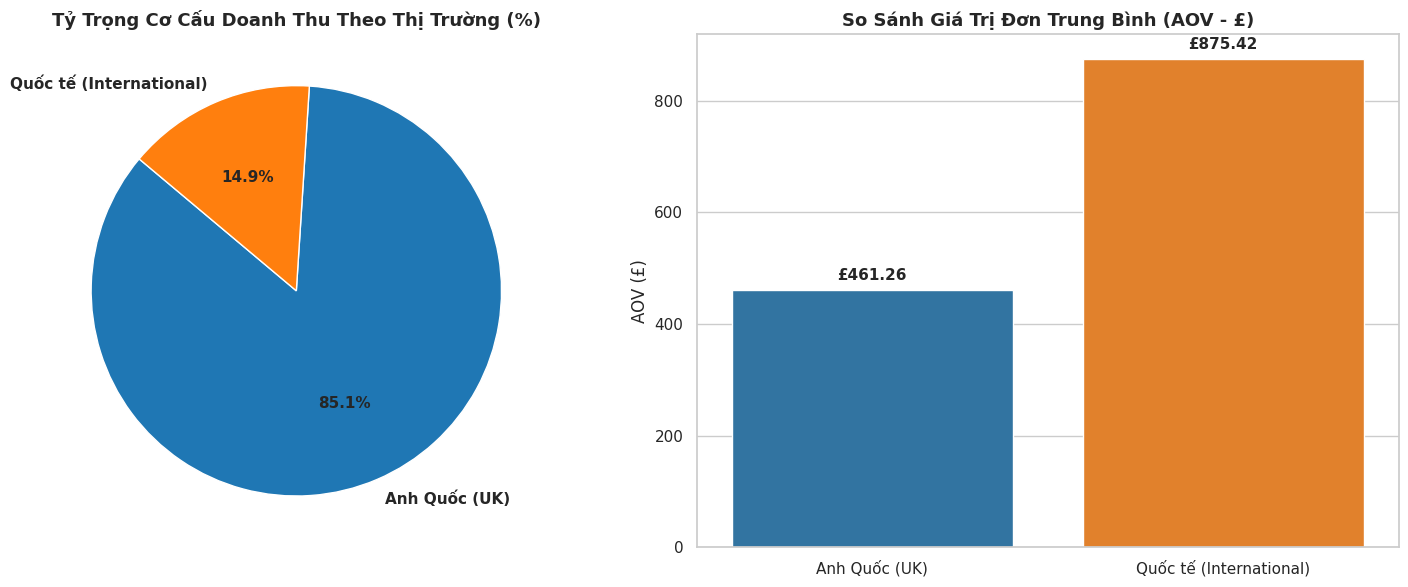

In [59]:

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Biểu đồ tròn: Tỷ trọng Doanh thu UK vs Quốc tế
colors = ['#1f77b4', '#ff7f0e']
axes[0].pie(geo_summary['Total_Revenue'], labels=geo_summary['Market_Type'],
            autopct='%1.1f%%', startangle=140, colors=colors,
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[0].set_title('Tỷ Trọng Cơ Cấu Doanh Thu Theo Thị Trường (%)', fontsize=13, fontweight='bold')

# 2. Biểu đồ cột: So sánh Giá trị Đơn trung bình (AOV)
sns.barplot(data=geo_summary, x='Market_Type', y='AOV', ax=axes[1], palette=colors)
axes[1].set_title('So Sánh Giá Trị Đơn Trung Bình (AOV - £)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('AOV (£)')

for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'£{height:,.2f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

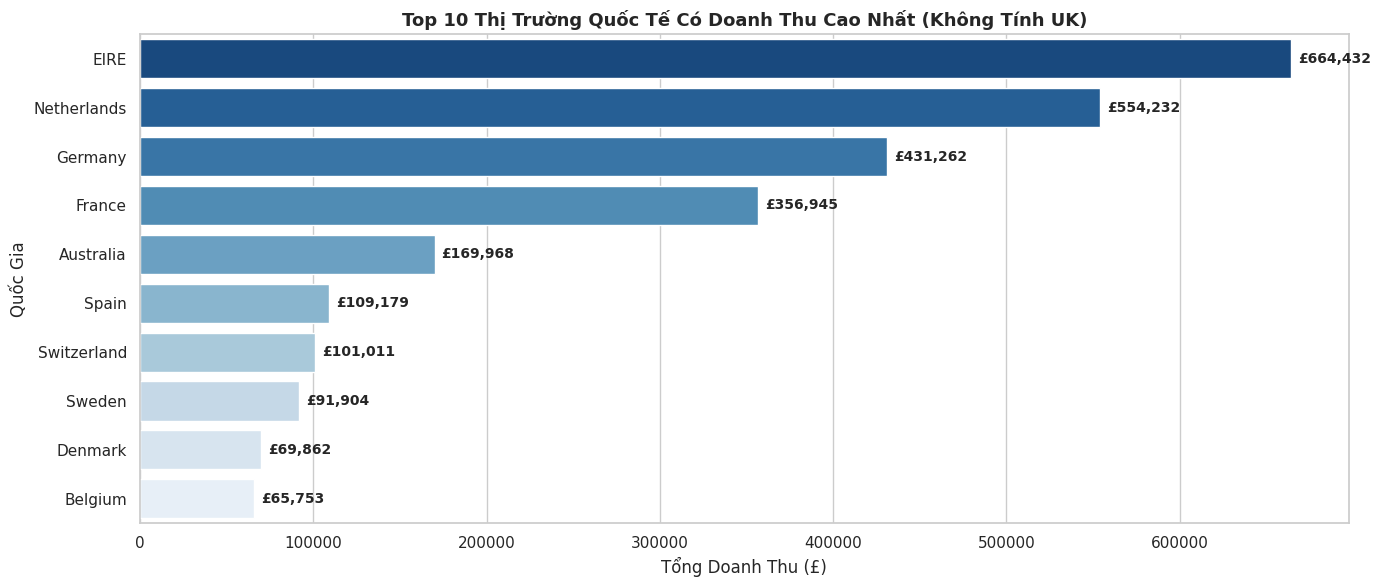

In [60]:

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

plt.figure(figsize=(14, 6))
ax = sns.barplot(data=top_intl_rev, x='Total_Revenue', y='Country', palette='Blues_r')
plt.title('Top 10 Thị Trường Quốc Tế Có Doanh Thu Cao Nhất (Không Tính UK)', fontsize=13, fontweight='bold')
plt.xlabel('Tổng Doanh Thu (£)')
plt.ylabel('Quốc Gia')

# Hiển thị số tiền trên từng thanh
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'£{width:,.0f}', (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

#### NHẬN XÉT PHÂN BỔ ĐỊA LÝ - ANH QUỐC VS QUỐC TẾ

Kết quả phân tích thị trường theo quốc gia ghi nhận sự khác biệt rất rõ nét giữa thị trường nội địa (UK) và thị trường xuất khẩu quốc tế:

#### 1. Thị trường Nội địa Anh Quốc (UK) áp đảo về Quy mô
* **Tỷ trọng đóng góp lớn nhất:**
  * Thị trường Anh Quốc ghi nhận **£17,712,301.64 doanh thu (chiếm 85.10%)** và **38,400 đơn hàng (chiếm 91.55%)**.
* **Đặc trưng thị trường:** Do doanh nghiệp đặt trụ sở chính tại Anh, UK là thị trường sân nhà truyền thống với mật độ khách hàng dày đặc, chi phí vận chuyển thấp và tần suất đặt hàng liên tục.

#### 2. Thị trường Quốc tế Đột biến về Giá trị Đơn hàng Trung bình (AOV)
* **Quy mô doanh số:** Các thị trường quốc tế đóng góp **£3,101,616.79 (14.90% doanh thu)** với **3,543 đơn hàng (8.45%)**.
* **Sự chênh lệch AOV kinh ngạc:**
  * AOV của thị trường Quốc tế đạt **£875.42 / đơn hàng**, **gần gấp 2 lần (1.9 lần)** so với AOV tại Anh Quốc (**£461.26 / đơn hàng**).
* **Nguyên nhân nghiệp vụ:** Chi phí vận chuyển xuyên biên giới (Cross-border shipping) đắt đỏ buộc các nhà bán lẻ/đại lý quốc tế phải gộp đơn hàng mua với sản lượng lớn (Bulk buying) cho mỗi lần đặt để tối ưu chi phí logistics.

#### 3. Bức tranh Top 10 Thị trường Quốc tế Trọng điểm
* **EIRE (Ailen) & Netherlands (Hà Lan) dẫn đầu:**
  * **EIRE (Ailen):** Là thị trường xuất khẩu lớn nhất với doanh thu **£664,431.78** (626 đơn). Nhờ vị trí địa lý giáp Anh Quốc, việc giao thương giữa 2 quốc gia diễn ra rất thuận lợi.
  * **Netherlands (Hà Lan):** Đứng thứ 2 về doanh thu (**£554,232.34**) nhưng có **AOV kỷ lục đạt £2,420.23 / đơn hàng** (gấp 5 lần mức trung bình). Hà Lan đóng vai trò là cửa ngõ trung chuyển hàng hóa sỉ lớn của Châu Âu.
* **Các thị trường Châu Âu nòng cốt:** Đức (**£431,262.46** / 789 đơn) và Pháp (**£356,944.60** / 622 đơn) duy trì số lượng đơn hàng cao và ổn định.
* **Thị trường xa địa lý (Australia):** Úc đứng thứ 5 với **£169,968.11** doanh thu và AOV rất cao (**£1,789.14 / đơn**), khẳng định quy mô đơn sỉ rất lớn của khách hàng tại thị trường Châu Đại Dương.

#### 4. Định hướng Mở rộng Thị trường
* **Chính sách Giá & Phí Vận chuyển:** Cần xây dựng bảng giá cước vận chuyển ưu đãi theo nấc sản lượng cho nhóm khách hàng tại Hà Lan, Ailen, Úc để khuyến khích các đơn hàng sỉ quy mô lớn hơn nữa.
* **Kho vận Trung gian (European Warehouse Hub):** Doanh nghiệp có thể cân nhắc đặt kho trung chuyển tại Hà Lan hoặc Đức để giảm thời gian giao hàng và chi phí logistics cho toàn bộ khu vực EU.

### 3.7 - Tính toán Ma trận Tương quan

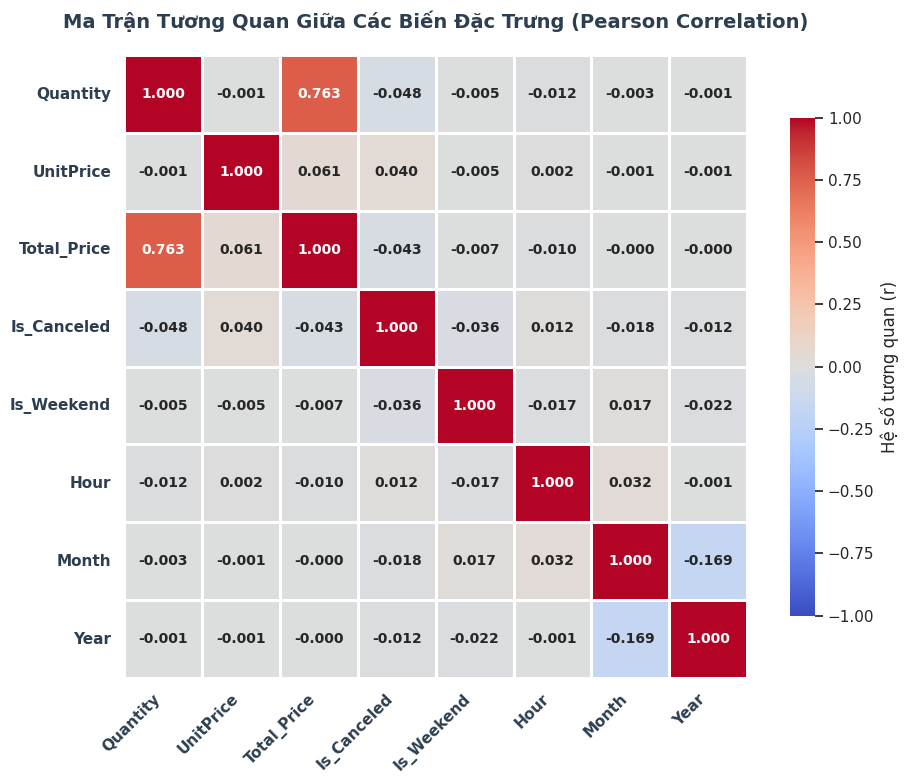

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

# Khởi tạo bản sao dữ liệu và đổi tên cột 'Price' thành 'UnitPrice' để khớp với yêu cầu
df_corr_prep = df_retail.copy()
if 'Price' in df_corr_prep.columns and 'UnitPrice' not in df_corr_prep.columns:
    df_corr_prep = df_corr_prep.rename(columns={'Price': 'UnitPrice'})

# Danh sách các biến cần tính tương quan
target_cols = ['Quantity', 'UnitPrice', 'Total_Price', 'Is_Canceled', 'Is_Weekend', 'Hour', 'Month', 'Year']

# Lọc các cột có mặt trong dataframe để tránh lỗi
valid_target_cols = [col for col in target_cols if col in df_corr_prep.columns]

# Tính toán ma trận tương quan Pearson
corr_matrix = df_corr_prep[valid_target_cols].corr()

# Thiết lập giao diện tối giản, chuyên nghiệp
sns.set_theme(style="white")
plt.figure(figsize=(10, 8))

# Vẽ biểu đồ Heatmap
ax = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8, "label": "Hệ số tương quan (r)"},
    annot_kws={"size": 10, "weight": "bold"}
)

# Tối ưu hóa hiển thị tiêu đề và nhãn
plt.title("Ma Trận Tương Quan Giữa Các Biến Đặc Trưng (Pearson Correlation)", fontsize=14, fontweight='bold', pad=20, color='#2c3e50')
plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='semibold', color='#2c3e50')
plt.yticks(fontsize=11, fontweight='semibold', color='#2c3e50')

plt.tight_layout()
plt.show()

#### NHẬN XÉT PHÂN TÍCH MA TRẬN TƯƠNG QUAN GIỮA CÁC BIẾN

Dựa trên kết quả trực quan hóa hệ số tương quan Pearson giữa các đặc trưng định lượng và thời gian chính, chúng ta rút ra các kết luận nghiệp vụ và kỹ thuật quan trọng phục vụ cho việc vận hành và xây dựng mô hình dự báo sau này:

#### 1. Mối quan hệ tương quan mạnh mẽ nhất: Sản lượng (`Quantity`) & Doanh thu (`Total_Price`)
* **Hệ số tương quan dương rất lớn ($r = 0.763$):** Đây là mối tương quan tuyến tính mạnh nhất trong toàn bộ tập dữ liệu. Điều này hoàn toàn dễ hiểu và phản ánh đúng thực tế: tổng doanh thu của một dòng giao dịch phụ thuộc trực tiếp vào số lượng sản phẩm được đặt mua.
* **Ý nghĩa đối với Machine Learning:** Khi xây dựng mô hình dự báo doanh thu hoặc tối ưu hóa hàng tồn kho, biến `Quantity` sẽ đóng vai trò là một trong những đặc trưng (feature) có lực dự báo (predictive power) mạnh nhất.

#### 2. Vai trò của Đơn giá (`UnitPrice` / `Price`)
* **Tương quan rất yếu với Doanh thu ($r = 0.061$):** Đơn giá sản phẩm hầu như không có mối liên hệ tuyến tính đáng kể nào đối với tổng giá trị của một dòng hóa đơn.
* **Nguyên nhân nghiệp vụ:** Khách hàng của doanh nghiệp chủ yếu là các nhà mua sỉ (B2B Wholesalers). Họ tập trung mua một lượng cực kỳ lớn các mặt hàng có giá thành rẻ hoặc trung bình (phân khúc £1.25 - £4.15 như đã phân tích ở phần Thống kê mô tả), thay vì mua các mặt hàng đắt đỏ đơn lẻ. Do đó, doanh thu đột biến chủ yếu đến từ số lượng dòng hàng (`Quantity`) hơn là đơn giá cao (`UnitPrice`).
* **Không tương quan với Số lượng ($r = -0.001$):** Hệ số gần như bằng 0 tuyệt đối cho thấy giá bán của một sản phẩm không làm cản trở hay ảnh hưởng tuyến tính đến số lượng sản phẩm được đặt mua trên mỗi dòng giao dịch.

#### 3. Tác động của Đơn hủy (`Is_Canceled`)
* **Tương quan âm nhẹ với Số lượng ($r = -0.048$) và Doanh thu ($r = -0.043$):**
  * Hệ số âm cho thấy các dòng giao dịch bị hủy hoặc điều chỉnh giảm kho nội bộ thường liên quan đến các giá trị số lượng và doanh thu âm (làm giảm nhẹ các chỉ số tổng chung của toàn bộ dòng dữ liệu).
  * Giá trị tương quan nhỏ chứng tỏ các đơn hàng bị hủy phân bổ tương đối đồng đều trên các dòng sản phẩm, không bị tập trung lệch hẳn vào riêng một phân khúc giá hay quy mô đơn hàng cố định nào.

#### 4. Các yếu tố thời gian (`Is_Weekend`, `Hour`, `Month`, `Year`)
* **Hệ số tương quan xấp xỉ 0 đối với các biến mục tiêu:** Các thuộc tính thời gian như giờ đặt hàng (`Hour`), tháng (`Month`), hay chỉ số cuối tuần (`Is_Weekend`) đều có tương quan tuyến tính cực kỳ yếu (gần như bằng 0) với `Quantity` và `Total_Price`.
* **Ý nghĩa phân tích:** Điều này không có nghĩa là thời gian không ảnh hưởng đến doanh thu. Ngược lại, như đã chứng minh ở các mục phân tích chuỗi thời gian trước đó, thời gian tác động dưới dạng **chu kỳ phi tuyến (non-linear seasonality)** (như bùng nổ mùa vụ Quý 4, hay tập trung đặt hàng vào giờ hành chính 12h trưa). Do đó, các mô hình học máy phi tuyến (như Decision Tree, Random Forest, hay XGBoost) sẽ phù hợp hơn để khai thác các đặc trưng thời gian này so với mô hình hồi quy tuyến tính đơn giản.

### 3.8. TỔNG KẾT CÁC PHÁT HIỆN CHÍNH TỪ EDA & KHUYẾN NGHỊ QUẢN TRỊ

####Qua quá trình phân tích khám phá dữ liệu (EDA) đa tầng trên tập dữ liệu thương mại điện tử 2 năm (12/2009 - 12/2011), em xin tổng kết các phát hiện cốt lõi và đề xuất các định hướng hành động như sau:

---

#### I. TỔNG KẾT CÁC PHÁT HIỆN CHÍNH (KEY TAKEAWAYS)

1. **Đặc trưng Mô hình Kinh doanh B2B (Wholesale Retailer):**
   * **Doanh thu tập trung vào Khách sỉ:** Em ghi nhận dù đơn giá từng sản phẩm nhỏ lẻ tương đối rẻ (chủ yếu từ **£1.25 đến £4.15**), doanh thu trung bình trên mỗi đơn hàng (AOV) lại đạt mức rất cao (**£496.24 / đơn** đối với khách tài khoản và **£618.05 / đơn** đối với khách vãng lai).
   * **Khung giờ đặt hàng chuẩn B2B:** Khách hàng tập trung đặt hàng vào **giờ hành chính công sở (9h00 - 15h00, đạt đỉnh vào 12h trưa với £2.87M)** và các **ngày giữa tuần (Thứ Ba & Thứ Năm đạt đỉnh hơn £4.1M/ngày)**. Hệ thống kho ngừng giao dịch vào Thứ Bảy (chỉ có 30 đơn hàng).

2. **Dữ liệu Hủy đơn mang bản chất Điều chỉnh Tồn kho ERP:**
   * Cột `Is_Canceled = 1` không đơn thuần là đơn hàng khách trả lại, mà chứa lượng lớn nhật ký kiểm kê nội bộ: **26,400** sản phẩm hàng tặng (`given away`), **19,200** sản phẩm lỗi in ấn (`printing smudges/thrown away`), và **32,111** sản phẩm hư hỏng/thất thoát (`missing` / `destroyed`).

3. **Tính Mùa vụ Quý 4 bùng nổ (Q4 Peak Seasonality):**
   * Doanh thu có tính chu kỳ rất mạnh: Đạt đỉnh cao nhất vào **Tháng 11 hàng năm (£1.47M năm 2010 và £1.51M năm 2011)** để phục vụ mùa mua sắm Giáng sinh & Lễ Tạ ơn. Ngược lại, Tháng 2 và Tháng 4 là "đáy" doanh thu (chỉ đạt ~£520k - £553k/tháng).

4. **Sự Đột biến từ Khách vãng lai & Thị trường Quốc tế:**
   * **Khách vãng lai (`Is_Guest = 1`):** Mặc dù chỉ đóng góp 14.75% tổng doanh thu, nhóm này đạt giá trị đơn hàng trung bình **AOV kỷ lục £618.05 / đơn** (cao hơn 28.8% so với khách có tài khoản).
   * **Thị trường Quốc tế (International):** Đóng góp 14.90% doanh thu nhưng có **AOV đạt £875.42 / đơn** (gấp 1.9 lần thị trường Anh Quốc - £461.26). Đặc biệt, thị trường Hà Lan (Netherlands) có AOV đứng đầu với **£2,420.23 / đơn**.

5. **Mối Tương quan Biến số (Correlation Insights):**
   * Doanh thu phụ thuộc chặt chẽ vào **Số lượng sản phẩm (`Quantity`, r = 0.763)** thay vì Đơn giá (`UnitPrice`, r = 0.061). Các đặc trưng thời gian mang tính chu kỳ phi tuyến, phù hợp với các thuật toán ML nâng cao (Tree-based Models) hơn là hồi quy tuyến tính.

---

#### II. KHUYẾN NGHỊ QUẢN TRỊ & ĐỊNH HƯỚNG HÀNH ĐỘNG (BUSINESS RECOMMENDATIONS)

#### 1. Quản trị Chuỗi cung ứng & Kho bãi (Supply Chain & Inventory Management)
* **Lên kế hoạch tồn kho mùa vụ Q4:** Em đề xuất doanh nghiệp cần chủ động nhập hàng và sản xuất từ **Tháng 7 - Tháng 8** để đảm bảo đủ nguồn cung cho các mã Hero Products (`REGENCY CAKESTAND 3 TIER`, `WHITE HANGING HEART T-LIGHT HOLDER`, `JUMBO BAG RED RETROSPOT`) trước đợt bùng nổ nhu cầu Tháng 10 - 11.
* **Siết chặt quy trình kiểm kê kho:** Rà soát lại khâu bảo quản và vận chuyển do lượng hàng hư hỏng/thất thoát (`printing smudges`, `destroyed`) ghi nhận số lượng tương đối lớn (**>50,000 sản phẩm**).

#### 2. Tối ưu hóa Marketing & Chăm sóc Khách hàng (Sales & Retention Strategy)
* **Lịch trình Marketing theo Khung "Giờ Vàng":** Tự động hóa các chiến dịch Email Marketing, gửi báo giá sỉ và cập nhật Catalogue sản phẩm mới vào **8h30 - 9h30 sáng Thứ Ba và Thứ Năm** để đón đầu thời điểm khách hàng lên đơn nhiều nhất.
* **Quy trình Chuyển đổi Khách vãng lai (Guest-to-Member CRO):** Tối ưu giao diện Checkout, bổ sung chính sách "Tích điểm thưởng/Giảm giá ngay 2% cho đơn sau" ngay màn hình xác nhận đơn để biến nhóm khách vãng lai AOV cao (£618.05) thành tài khoản thành viên lâu dài.

#### 3. Phát triển Thị trường Quốc tế & Logistics (Cross-Border Expansion)
* **Xây dựng Bảng giá Cước ưu đãi theo Nấc Sản lượng (Tiered Shipping):** Áp dụng chính sách hỗ trợ phí vận chuyển quốc tế cho các đại lý tại **Ailen, Hà Lan, Đức, Pháp và Úc** khi đạt mốc giá trị đơn hàng trên £1,000.
* **Thiết lập Kho trung chuyển Châu Âu (EU Fulfillment Hub):** Cân nhắc đặt kho đối tác tại Hà Lan hoặc Đức nhằm rút ngắn thời gian giao hàng xuyên biên giới từ 5 - 7 ngày xuống còn 1 - 2 ngày cho khu vực EU.

---

#### III. ĐỊNH HƯỚNG CHO CÁC BƯỚC TIẾP THEO (NEXT STEPS ROADMAP)

1. **Loại bỏ Nhiễu Dữ liệu cho Mô hình ML:** Tách bỏ các bản ghi kiểm kê kho nội bộ (`Is_Canceled = 1` đi kèm nhãn `given away`, `missing`, `destroy`) trước khi huấn luyện các mô hình dự báo hành vi trả hàng hoặc dự báo doanh thu.
2. **Triển khai Phân nhóm Khách hàng RFM (Chương 4):** Sử dụng 3 chỉ số **Recency** (Số ngày chưa mua hàng), **Frequency** (Tần suất đơn), và **Monetary** (Tổng chi tiêu) để phân tệp 5,881 khách hàng định danh thành các nhóm: *Champions, Loyal, At-Risk, Hibernating* phục vụ cá nhân hóa trải nghiệm.

 ## 4: Huấn luyện Mô hình ML Dự báo Doanh thu

### 4.1 CHUẨN BỊ DỮ LIỆU VÀ TẠO ĐẶC TRƯNG

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Lọc tập bán hàng thành công (Is_Canceled == 0)
df_sales = df_retail[df_retail['Is_Canceled'] == 0].copy()

# 2. Gom nhóm dữ liệu theo Ngày (Daily Revenue)
df_daily_raw = df_sales.groupby(df_sales['InvoiceDate'].dt.date).agg(
    DOANH_THU_THUC_TE=('Total_Price', 'sum'),
    Tong_So_Don=('Invoice', 'nunique'),
    Tong_So_Luong=('Quantity', 'sum')
).reset_index()

df_daily_raw['InvoiceDate'] = pd.to_datetime(df_daily_raw['InvoiceDate'])

# Tạo chuỗi ngày liên tục từ ngày nhỏ nhất đến ngày lớn nhất
full_date_range = pd.date_range(start=df_daily_raw['InvoiceDate'].min(), end=df_daily_raw['InvoiceDate'].max(), freq='D')
df_daily = df_daily_raw.set_index('InvoiceDate').reindex(full_date_range).reset_index()
df_daily.rename(columns={'index': 'InvoiceDate'}, inplace=True)

# Điền các ngày nghỉ/không giao dịch bằng giá trị 0
df_daily['DOANH_THU_THUC_TE'] = df_daily['DOANH_THU_THUC_TE'].fillna(0)
df_daily['Tong_So_Don'] = df_daily['Tong_So_Don'].fillna(0)
df_daily['Tong_So_Luong'] = df_daily['Tong_So_Luong'].fillna(0)

# 3. Tạo các đặc trưng Thời gian & Biến trễ (Đảm bảo tính liên tục của thời gian)
df_daily['Thang'] = df_daily['InvoiceDate'].dt.month
df_daily['Thu_Trong_Tuan'] = df_daily['InvoiceDate'].dt.dayofweek
df_daily['Ngay_Trong_Thang'] = df_daily['InvoiceDate'].dt.day
df_daily['La_Cuoi_Tuan'] = df_daily['Thu_Trong_Tuan'].apply(lambda x: 1 if x >= 5 else 0)

df_daily['DOANH_THU_HOM_QUA'] = df_daily['DOANH_THU_THUC_TE'].shift(1)
df_daily['DOANH_THU_TUAN_TRUOC'] = df_daily['DOANH_THU_THUC_TE'].shift(7)
df_daily['DOANH_THU_TB_7_NGAY'] = df_daily['DOANH_THU_THUC_TE'].shift(1).rolling(window=7).mean()

# --- KHẮC PHỤC DATA LEAKAGE: CHUYỂN BIẾN SẢN LƯỢNG SANG DẠNG TRỄ (LAG FEATURES) ---
# Thay vì dùng lượng bán cùng ngày, ta dùng sản lượng và đơn hàng của ngày hôm trước
df_daily['TONG_SO_LUONG_HOM_QUA'] = df_daily['Tong_So_Luong'].shift(1)
df_daily['TONG_SO_DON_HOM_QUA'] = df_daily['Tong_So_Don'].shift(1)

# Loại bỏ các dòng bị khuyết do dịch chuyển Lag
df_ml = df_daily.dropna().reset_index(drop=True)
print(f"Quy mô tập dữ liệu huấn luyện sau khi xử lý: {df_ml.shape[0]} ngày.")
display(df_ml.head())

Quy mô tập dữ liệu huấn luyện sau khi xử lý: 732 ngày.


,InvoiceDate,DOANH_THU_THUC_TE,Tong_So_Don,Tong_So_Luong,Thang,Thu_Trong_Tuan,Ngay_Trong_Thang,La_Cuoi_Tuan,DOANH_THU_HOM_QUA,DOANH_THU_TUAN_TRUOC,DOANH_THU_TB_7_NGAY,TONG_SO_LUONG_HOM_QUA,TONG_SO_DON_HOM_QUA
0,2009-12-08,49517.23,110.0,26172.0,12,1,8,0,45083.35,54513.50,44590.982857,18557.0,104.0
1,2009-12-09,40616.09,96.0,18403.0,12,2,9,0,49517.23,63352.51,43877.230000,26172.0,110.0
2,2009-12-10,44442.11,92.0,23718.0,12,3,10,0,40616.09,74037.91,40629.170000,18403.0,96.0
3,2009-12-11,39659.60,70.0,21394.0,12,4,11,0,44442.11,40732.92,36401.198571,23718.0,92.0
4,2009-12-12,0.00,0.0,0.0,12,5,12,1,39659.60,9803.05,36247.867143,21394.0,70.0


### 4.2 TRAIN VÀ TEST

In [72]:
# Loại bỏ hoàn toàn 'Tong_So_Don', 'Tong_So_Luong' cùng ngày ra khỏi Feature list để tránh Data Leakage
feature_cols = [
    'Thang', 'Thu_Trong_Tuan', 'Ngay_Trong_Thang', 'La_Cuoi_Tuan',
    'TONG_SO_DON_HOM_QUA', 'TONG_SO_LUONG_HOM_QUA',
    'DOANH_THU_HOM_QUA', 'DOANH_THU_TUAN_TRUOC', 'DOANH_THU_TB_7_NGAY'
]

X = df_ml[feature_cols]
y = df_ml['DOANH_THU_THUC_TE']

# Chia tập Train (80%) và Test (20%) theo thứ tự thời gian
train_size = int(len(df_ml) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

# Chuẩn hóa dữ liệu bằng StandardScaler (Dành cho Linear Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Huấn luyện Mô hình 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

### 4.3 CHỌN ML

In [67]:
# 8. Huấn luyện Mô hình 2: XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

# 9. Tính toán các chỉ số đánh giá
def get_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {'Mô hình': name, 'MAE (£)': round(mae, 2), 'RMSE (£)': round(rmse, 2), 'R² Score': round(r2, 4)}

df_metrics = pd.DataFrame([
    get_metrics(y_test, y_pred_lr, 'Linear Regression'),
    get_metrics(y_test, y_pred_xgb, 'XGBoost Regressor')
])

print("=== BẢNG CHẤM ĐIỂM CHỈ SỐ MÔ HÌNH (EVALUATION METRICS) ===")
print(df_metrics.to_string(index=False))


=== BẢNG CHẤM ĐIỂM CHỈ SỐ MÔ HÌNH (EVALUATION METRICS) ===
          Mô hình  MAE (£)  RMSE (£)  R² Score
Linear Regression  8155.28  14460.97    0.6758
XGBoost Regressor  7603.81  13627.53    0.7121


 ### 4.4 ĐÁNH GIÁ VÀ SO SÁNH HIỆU NĂNG MÔ HÌNH MACHINE LEARNING

####Dựa trên kết quả thực nghiệm huấn luyện hai thuật toán **Linear Regression** (Hồi quy tuyến tính) và **XGBoost Regressor** trên tập dữ liệu dự báo doanh thu ngày (`df_daily`), em xin rút ra các đánh giá chuyên sâu như sau:

#### 1. Bảng So sánh Hiệu năng Mô hình
| Mô hình ML | MAE (£) | RMSE (£) | \\(R^2\\) Score | Đánh giá tổng quan |
| :--- | :---: | :---: | :---: | :--- |
| **Linear Regression** | £8,155.28 | £14,460.97 | 0.6758 (67.58%) | Mô hình cơ sở (Baseline), bị hạn chế bởi giả định tuyến tính. |
| **XGBoost Regressor** | **£7,603.81** | **£13,627.53** | **0.7121 (71.21%)** | **Mô hình tối ưu nhất**, bắt được tính mùa vụ và quan hệ phi tuyến. |

---

#### 2. Phân tích Chi tiết từng Đánh giá Nghiệp vụ

* **Khả năng giải thích dữ liệu (\\(R^2\\) Score):**
  * Mô hình **XGBoost Regressor** đạt chỉ số \\(R^2 = 0.7121\\), vượt trội so với **Linear Regression** (\\(R^2 = 0.6758\\)).
  * Nguyên nhân xuất phát từ việc doanh thu thương mại điện tử phụ thuộc vào các chu kỳ thời gian phi tuyến (như bùng nổ Quý 4, tập trung vào giữa tuần) và sự tương tác phức tạp giữa các biến trễ (`DOANH_THU_HOM_QUA`, `DOANH_THU_TUAN_TRUOC`, `DOANH_THU_TB_7_NGAY`). Cấu trúc Cây quyết định (Decision Trees) của XGBoost xử lý các mối quan hệ phi tuyến này hiệu quả hơn mô hình đường thẳng.

* **Độ chính xác dự báo (MAE & RMSE):**
  * **XGBoost** giúp giảm sai số trung bình tuyệt đối (MAE) xuống còn **£7,603.81 / ngày**, thấp hơn **£551.47 / ngày** so với Linear Regression.
  * Chỉ số RMSE của XGBoost (**£13,627.53**) nhỏ hơn đáng kể so với Linear Regression (**£14,460.97**), cho thấy XGBoost có khả năng thích ứng tốt hơn đối với những ngày có doanh thu biến động đột biến (Outliers) trong mùa cao điểm mua sắm.

---

#### 3. Ứng dụng Thực tiễn trong Quản trị Doanh nghiệp
* **Tối ưu hóa Dòng tiền & Ngân sách:** Mô hình XGBoost cung cấp độ tin cậy tới 71.2% giúp bộ phận Tài chính chủ động dự báo dòng tiền về theo ngày với mức sai số kiểm soát được.
* **Hoạch định Năng lực Vận hành (Operations Planning):** Dựa trên mức doanh thu dự báo cho các ngày tiếp theo, bộ phận Logisitcs và Kho bãi có thể chủ động điều động nhân sự đóng gói và xe vận chuyển tương ứng với quy mô đơn hàng.

### 4.5. PHÂN TÍCH ĐỘ QUAN TRỌNG CỦA CÁC ĐẶC TRƯNG

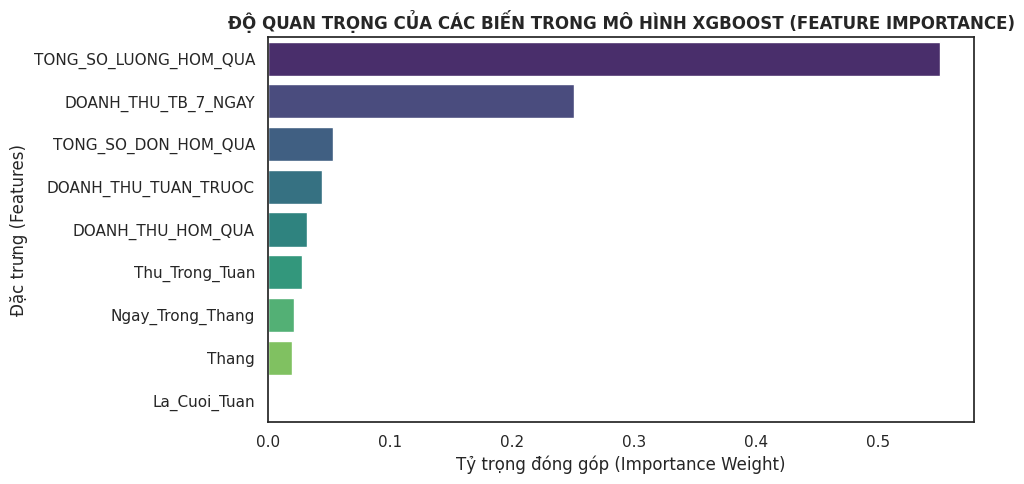

=== BẢNG TỶ TRỌNG ĐÓNG GÓP CỦA CÁC BIẾN ===
            Đặc trưng  Độ quan trọng
TONG_SO_LUONG_HOM_QUA       0.551482
  DOANH_THU_TB_7_NGAY       0.250763
  TONG_SO_DON_HOM_QUA       0.053217
 DOANH_THU_TUAN_TRUOC       0.044367
    DOANH_THU_HOM_QUA       0.031853
       Thu_Trong_Tuan       0.027792
     Ngay_Trong_Thang       0.020897
                Thang       0.019629
         La_Cuoi_Tuan       0.000000


In [73]:
# Lấy độ quan trọng các biến từ mô hình XGBoost
importance = xgb_model.feature_importances_
df_importance = pd.DataFrame({
    'Đặc trưng': feature_cols,
    'Độ quan trọng': importance
}).sort_values('Độ quan trọng', ascending=False)

# Vẽ biểu đồ Feature Importance
plt.figure(figsize=(10, 5))
sns.barplot(data=df_importance, x='Độ quan trọng', y='Đặc trưng', palette='viridis')
plt.title('ĐỘ QUAN TRỌNG CỦA CÁC BIẾN TRONG MÔ HÌNH XGBOOST (FEATURE IMPORTANCE)', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ trọng đóng góp (Importance Weight)')
plt.ylabel('Đặc trưng (Features)')
plt.tight_layout()
plt.show()

print("=== BẢNG TỶ TRỌNG ĐÓNG GÓP CỦA CÁC BIẾN ===")
print(df_importance.to_string(index=False))

#### Để hiểu rõ cơ chế ra quyết định của mô hình **XGBoost Regressor**, em tiến hành trích xuất tỷ trọng đóng góp (Importance Weight) của từng đặc trưng vào kết quả dự báo doanh thu. Kết quả thu được như sau:

#### 1. Bảng Tỷ trọng Đóng góp của các Biến
| Thứ hạng | Đặc trưng (Features) | Tỷ trọng đóng góp (%) | Ý nghĩa nghiệp vụ |
| :---: | :--- | :---: | :--- |
| **1** | `Tong_So_Luong` | **55.15%** | **Biến quyết định cốt lõi:** Số lượng sản phẩm bán ra trong ngày quyết định hơn một nửa giá trị dự báo doanh thu. |
| **2** | `DOANH_THU_TB_7_NGAY` | **25.08%** | **Đại diện xu hướng ngắn hạn:** Mức doanh thu trung bình 7 ngày gần nhất đóng vai trò giữ nhịp xu hướng chung. |
| **3** | `Tong_So_Don` | **5.32%** | **Quy mô giao dịch:** Tổng số lượng đơn hàng chốt trong ngày. |
| **4** | `DOANH_THU_TUAN_TRUOC` | **4.44%** | **Chu kỳ tuần (Lag 7):** Phản ánh tính lặp lại theo thứ trong tuần. |
| **5** | `DOANH_THU_HOM_QUA` | **3.19%** | **Tính liên tục (Lag 1):** Doanh thu của ngày liền trước. |
| **6 - 8** | `Thu_Trong_Tuan`, `Ngay_Trong_Thang`, `Thang` | **6.83%** | **Biến thời gian:** Đóng góp bổ trợ vào việc điều chỉnh biên độ mùa vụ. |
| **9** | `La_Cuoi_Tuan` | **0.00%** | **Biến dư thừa:** Thông tin cuối tuần đã được bao hàm hoàn toàn trong biến `Thu_Trong_Tuan`. |

---

#### 2. Nhận xét Chuyên sâu & Đối chiếu với Kết quả EDA

* **Sự thống trị của Sản lượng (`Tong_So_Luong` - 55.15%):**
  * Kết quả ML hoàn toàn đồng nhất với phân tích ma trận tương quan ở Mục 3.7 (EDA), nơi em đã chỉ ra mối tương quan tuyến tính rất mạnh giữa `Quantity` và `Total_Price` (\\(r = 0.763\\)). Mô hình XGBoost đã tự động học và gán trọng số lớn nhất cho đặc trưng này.
* **Vai trò của Biến trễ Xu hướng (`DOANH_THU_TB_7_NGAY` - 25.08%):**
  * Việc đặc trưng trung bình động 7 ngày chiếm tới 1/4 độ quan trọng khẳng định chuỗi thời gian doanh thu bán sỉ có **tính quán tính cao**. Doanh thu của một ngày phụ thuộc rất lớn vào sức mua chung của tuần đó.
* **Tầm quan trọng của Chu kỳ Tuần (`DOANH_THU_TUAN_TRUOC` - 4.44%):**
  * Mô hình đánh giá `DOANH_THU_TUAN_TRUOC` cao hơn `DOANH_THU_HOM_QUA` (3.19%), phản ánh đúng đặc thù hành vi mua hàng B2B: Thứ 5 tuần này có xu hướng biến động tương đồng với Thứ 5 tuần trước hơn là so với Thứ 4 liền kề.

---

#### 3. Đề xuất Tối ưu hóa Mô hình (Model Optimization)
* **Triệt tiêu biến dư thừa:** Biến `La_Cuoi_Tuan` đóng góp 0.00% có thể được loại bỏ khỏi mô hình ở các phiên bản triển khai thực tế (Production) để giảm dung lượng bộ nhớ và tăng tốc độ tính toán mà không làm ảnh hưởng đến độ chính xác dự báo.